## Load Model

In [1]:
import numpy as np
import torch
import os

from matplotlib import pyplot as plt
import seaborn as sns
from scipy import stats

%load_ext autoreload
%autoreload 2

from utils import generate_run_ID
from place_cells import PlaceCells
from direction_cells import DirectionCells
from trajectory_generator_seed import TrajectoryGenerator
from models import LMN_PaS_Conj_mEC
from trainer import Trainer

from scipy.signal import correlate
from tqdm import tqdm
from scipy.ndimage import gaussian_filter1d



In [2]:
# Training options and hyperparameters
class Options:
    pass
options = Options()

options.save_dir = './models_4layer/' 
options.n_steps = 1000    # number of training steps
options.epochs = 201       # number of training epochs
options.batch_size = 500      # number of trajectories per batch
options.sequence_length = 20  # number of steps in trajectory
options.learning_rate = 1e-4  # gradient descent learning rate
#early stopping 
options.freeze_pas_patience = 100
options.freeze_pas_min_delta = 1e-8 #0.0001


options.Nd = 128           # number of direction cells
options.Np = 512           # number of place cells
options.Nlmn = 256        # number of LMN cells
options.Npas = 256        # number of PaS cells
options.Ncg = 512         # number of conjuntive mEC cells
options.Ng = 512         # number of mEC cells

options.place_cell_rf = 0.12  # width of place cell center tuning curve (m)
options.surround_scale = 2    # if DoG, ratio of sigma2^2 to sigma1^2
options.direction_cell_rf = 30*np.pi/180  # width of direction cell tuning curve (radians)
options.activation = 'relu'   # recurrent nonlinearity
options.weight_decay_lmn = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_pas = 1e-4   # strength of weight decay on recurrent weights in lmn
options.weight_decay_conj = 0 # strength of weight decay on recurrent weights in conj RNN
options.weight_decay_mec = 0  # strength of weight decay on recurrent weights in mEC RNN
options.use_pas_layernorm = False  # apply LayerNorm to PaS before feeding Conj
options.DoG = True            # use difference of gaussians tuning curves
options.periodic = False
options.box_width = 2.2       # width of training environment
options.box_height = 2.2      # height of training environment

options.device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

options.run_ID = generate_run_ID(options)

place_cells = PlaceCells(options)
direction_cells = DirectionCells(options)
    
model = LMN_PaS_Conj_mEC(options, direction_cells, place_cells).to(options.device)

trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=place_cells)

ckpt_path = os.path.join(options.save_dir, options.run_ID, 'most_recent_model.pth')

if os.path.exists(ckpt_path):
    trainer = Trainer(options, model, trajectory_generator, restore=True)
    print(f'Checkpoint exists, skip training: {ckpt_path}')
else:
    trainer = Trainer(options, model, trajectory_generator, restore=False)
    trainer.train(n_epochs=options.epochs, n_steps=options.n_steps, save=True)



Restored trained model from ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_201_batch_500_length_20_lr_00001/most_recent_model.pth
Checkpoint exists, skip training: ./models_4layer/HRNN_LNpas_0_Np_512_Ncg_512_Ng_512_rf_012_WD_conj_0_WD_mec_0_Nd_128_Nlmn_256_Npas_256_dir_rf_0_WD_lmn_00001_WD_pas_00001_epochs_201_batch_500_length_20_lr_00001/most_recent_model.pth


In [3]:
# Helper Functions
def break_at_wrap(angle_series, wrap=np.pi):
    a = np.asarray(angle_series).squeeze()
    out = a.astype(float).copy()
    jumps = np.abs(np.diff(out))
    out[1:][jumps > wrap] = np.nan
    return out

def wrap_to_pi(x):
    return (x + np.pi) % (2 * np.pi) - np.pi

def angular_error(true_ang, pred_ang, angle_range=2 * np.pi):
    d = np.abs(true_ang - pred_ang)
    return np.minimum(d, angle_range - d)

def smooth_columns_boxcar(arr, win=5):
    arr = np.asarray(arr, dtype=float)
    if win <= 1:
        return arr.copy()
    if win % 2 == 0:
        raise ValueError("win must be odd.")
    kernel = np.ones(win, dtype=float) / win
    pad = win // 2
    out = np.empty_like(arr, dtype=float)
    for j in range(arr.shape[1]):
        col = arr[:, j]
        col_pad = np.pad(col, pad_width=pad, mode='edge')
        out[:, j] = np.convolve(col_pad, kernel, mode='valid')
    return out

def break_rows_at_jump(row_series, jump_thresh=None, n_rows=None):
    r = np.asarray(row_series).astype(float).copy()
    if jump_thresh is None:
        if n_rows is None:
            raise ValueError("Need n_rows if jump_thresh is None.")
        jump_thresh = n_rows / 2
    jumps = np.abs(np.diff(r))
    r[1:][jumps > jump_thresh] = np.nan
    return r

def get_act_fn_from_name(name):
    if name == "tanh":
        return torch.tanh
    elif name == "relu":
        return torch.relu
    else:
        raise ValueError(f"Unsupported nonlinearity: {name}")

# --------------------------------------------------
# batch unpacking
# --------------------------------------------------
def unpack_batch(batch):
    """
    Supports:
      direction-only:
          batch = (inputs, dc_outputs, mdir)
          inputs = (ang_v, init_dir_actv)
      joint place+direction:
          batch = (inputs, outputs, targets)
          inputs  = (s, init_actp, ang_v, init_dir_actv)
          outputs = (place_outputs, dc_outputs)
          targets = (pos, mdir)
    Returns:
      ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos
    """
    if len(batch) != 3:
        raise ValueError("Expected batch tuple of length 3.")
    a, b, c = batch
    if isinstance(a, tuple) and len(a) == 2:
        ang_v, init_dir_actv = a
        dc_outputs = b
        mdir = c
        s = None
        init_actp = None
        place_outputs = None
        pos = None
        return ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos
    if isinstance(a, tuple) and len(a) == 4:
        s, init_actp, ang_v, init_dir_actv = a
        place_outputs, dc_outputs = b
        pos, mdir = c
        return ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos
    raise ValueError("Unsupported batch format.")

# --------------------------------------------------
# one-step recurrences
# --------------------------------------------------
def pas_one_step(model, lmn_input_t, r_t, a_t=None):
    """
    One step of vanilla PaS RNN.
    Returns:
      r_next, a_next
    """
    if hasattr(model.PaSRNN, "weight_ih_l0") and hasattr(model.PaSRNN, "weight_hh_l0"):
        W_ih = model.PaSRNN.weight_ih_l0
        W_hh = model.PaSRNN.weight_hh_l0
        b_ih = model.PaSRNN.bias_ih_l0 if getattr(model.PaSRNN, "bias", False) else None
        b_hh = model.PaSRNN.bias_hh_l0 if getattr(model.PaSRNN, "bias", False) else None
        act_fn = get_act_fn_from_name(model.PaSRNN.nonlinearity)
        pre = lmn_input_t @ W_ih.T + r_t @ W_hh.T
        if b_ih is not None:
            pre = pre + b_ih
        if b_hh is not None:
            pre = pre + b_hh
        r_next = act_fn(pre)
        a_next = torch.zeros_like(r_next)
        return r_next, a_next
    else:
        raise AttributeError("Unsupported PaSRNN type: cannot find vanilla RNN weights.")

def conj_one_step(model, drive_in, h_t):
    """
    One step of Conj RNN.
    Input:
      drive_in : [B, Npas + 1]
      h_t      : [B, Ncg]
    """
    if not (hasattr(model, "conjRNN") and hasattr(model.conjRNN, "weight_ih_l0")):
        raise AttributeError("Model does not have a vanilla conjRNN.")
    W_ih = model.conjRNN.weight_ih_l0
    W_hh = model.conjRNN.weight_hh_l0
    b_ih = model.conjRNN.bias_ih_l0 if getattr(model.conjRNN, "bias", False) else None
    b_hh = model.conjRNN.bias_hh_l0 if getattr(model.conjRNN, "bias", False) else None
    act_fn = get_act_fn_from_name(model.conjRNN.nonlinearity)
    pre = drive_in @ W_ih.T + h_t @ W_hh.T
    if b_ih is not None:
        pre = pre + b_ih
    if b_hh is not None:
        pre = pre + b_hh
    return act_fn(pre)

def mec_one_step(model, conj_t, h_t):
    """
    One step of mEC RNN.
    Input:
      conj_t : [B, Ncg]
      h_t    : [B, Ng]
    """
    if not (hasattr(model, "mECRNN") and hasattr(model.mECRNN, "weight_ih_l0")):
        raise AttributeError("Model does not have a vanilla mECRNN.")
    W_ih = model.mECRNN.weight_ih_l0
    W_hh = model.mECRNN.weight_hh_l0
    b_ih = model.mECRNN.bias_ih_l0 if getattr(model.mECRNN, "bias", False) else None
    b_hh = model.mECRNN.bias_hh_l0 if getattr(model.mECRNN, "bias", False) else None
    act_fn = get_act_fn_from_name(model.mECRNN.nonlinearity)
    pre = conj_t @ W_ih.T + h_t @ W_hh.T
    if b_ih is not None:
        pre = pre + b_ih
    if b_hh is not None:
        pre = pre + b_hh
    return act_fn(pre)

# --------------------------------------------------
# rollout helpers
# --------------------------------------------------
def rollout_pas_from_lmn_sequence(model, lmn_seq, init_dir_actv):
    T, B, _ = lmn_seq.shape
    device = lmn_seq.device
    dtype = lmn_seq.dtype
    if not hasattr(model, "PaSEncoder"):
        raise AttributeError("Model must have PaSEncoder.")
    r_t = model.PaSEncoder(init_dir_actv)
    a_t = torch.zeros_like(r_t)
    Npas = r_t.shape[1]
    pas_seq = torch.zeros((T, B, Npas), device=device, dtype=dtype)
    adap_seq = torch.zeros((T, B, Npas), device=device, dtype=dtype)
    for t in range(T):
        r_t, a_t = pas_one_step(model, lmn_seq[t], r_t, a_t)
        pas_seq[t] = r_t
        adap_seq[t] = a_t
    return pas_seq, adap_seq

def rollout_conj_mec_from_pas_sequence(model, s_seq, init_actp, pas_seq):
    """
    Rollout both Conj and mEC from a PaS sequence.
    Returns:
      conj_seq : [T, B, Ncg]
      mec_seq  : [T, B, Ng]
    """
    if s_seq is None or init_actp is None:
        raise ValueError("Need speed input and initial place activity to rollout Conj and mEC.")
    T, B, _ = pas_seq.shape
    device = pas_seq.device
    dtype = pas_seq.dtype
    h_conj = model.conjEncoder(init_actp)
    h_mec = model.mECEncoder(init_actp)
    Ncg = h_conj.shape[1]
    Ng = h_mec.shape[1]
    conj_seq = torch.zeros((T, B, Ncg), device=device, dtype=dtype)
    mec_seq = torch.zeros((T, B, Ng), device=device, dtype=dtype)
    for t in range(T):
        pas_t = model.PaSNorm(pas_seq[t]) if model.PaSNorm is not None else pas_seq[t]
        drive_in = torch.cat([s_seq[t], pas_t], dim=-1)
        h_conj = conj_one_step(model, drive_in, h_conj)
        h_mec = mec_one_step(model, h_conj, h_mec)
        conj_seq[t] = h_conj
        mec_seq[t] = h_mec
    return conj_seq, mec_seq

def run_normal_lmn_pas_conj_mec_rollout(model, inputs):
    """
    Normal rollout with no shutdown and no reset.
    inputs: (s, init_actp, ang_v, init_dir_actv)
    Returns:
      lmn_seq, pas_seq, adap_seq, conj_seq, mec_seq
    """
    s, init_actp, ang_v, init_dir_actv = inputs
    with torch.no_grad():
        lmn_seq = model.Lmn((ang_v, init_dir_actv))
        pas_seq, adap_seq = rollout_pas_from_lmn_sequence(model, lmn_seq, init_dir_actv)
        conj_seq, mec_seq = rollout_conj_mec_from_pas_sequence(model, s, init_actp, pas_seq)
    return lmn_seq, pas_seq, adap_seq, conj_seq, mec_seq

# --------------------------------------------------
# plotting helpers
# --------------------------------------------------
def build_colored_line_by_block(ax, xy, block_len, cmap='plasma', lw=2.5, alpha=1.0, zorder=3, sub_per_step=30):
    """
    Smooth color change WITHIN each block.
    Each original step segment is subdivided into many tiny segments.
    """
    xy = np.asarray(xy, dtype=float)
    if xy.ndim != 2 or xy.shape[1] != 2:
        raise ValueError("xy must have shape [T, 2].")
    if xy.shape[0] < 2:
        return None
    if block_len < 1:
        raise ValueError("block_len must be >= 1")
    if sub_per_step < 1:
        raise ValueError("sub_per_step must be >= 1")
    T = xy.shape[0]
    n_steps = T - 1
    fine_segments = []
    fine_colors = []
    for step_idx in range(n_steps):
        p0 = xy[step_idx]
        p1 = xy[step_idx + 1]
        pos_in_block = step_idx % block_len
        for j in range(sub_per_step):
            a0 = j / sub_per_step
            a1 = (j + 1) / sub_per_step
            q0 = (1.0 - a0) * p0 + a0 * p1
            q1 = (1.0 - a1) * p0 + a1 * p1
            fine_segments.append([q0, q1])
            color_val = (pos_in_block + (j + 0.5) / sub_per_step) / max(block_len - 1, 1)
            fine_colors.append(np.clip(color_val, 0.0, 1.0))
    fine_segments = np.asarray(fine_segments, dtype=float)
    fine_colors = np.asarray(fine_colors, dtype=float)
    lc = LineCollection(fine_segments, cmap=cmap, norm=Normalize(vmin=0.0, vmax=1.0))
    lc.set_array(fine_colors)
    lc.set_linewidth(lw)
    lc.set_alpha(alpha)
    lc.set_zorder(zorder)
    lc.set_capstyle('round')
    lc.set_joinstyle('round')
    ax.add_collection(lc)
    return lc

def rotate_xy_to_horizontal(true_xy, pred_xy):
    """
    Rotate both trajectories so that the true trajectory start->end direction is horizontal.
    Also center both around the true trajectory start point.
    """
    true_xy = np.asarray(true_xy, dtype=float)
    pred_xy = np.asarray(pred_xy, dtype=float)
    origin = true_xy[0].copy()
    true_centered = true_xy - origin
    pred_centered = pred_xy - origin
    delta = true_centered[-1] - true_centered[0]
    theta = np.arctan2(delta[1], delta[0])
    c = np.cos(-theta)
    s = np.sin(-theta)
    R = np.array([[c, -s], [s,  c]])
    true_rot = true_centered @ R.T
    pred_rot = pred_centered @ R.T
    return true_rot, pred_rot, theta

def rotate_points_to_vertical(points_xy, heading_angle):
    """
    Rotate so heading becomes vertical upward (+y).
    """
    rot_theta = (np.pi / 2.0) - heading_angle
    c = np.cos(rot_theta)
    s = np.sin(rot_theta)
    R = np.array([[c, -s], [s,  c]])
    return points_xy @ R.T

def build_aligned_block_trajectories(pred_xy, true_dir, block_len):
    """
    pred_xy : [T, 2]
    true_dir: [T]
    Returns:
      aligned_blocks: [n_blocks, block_len-1, 2]
      block_ids:      [n_blocks]
      block_parity:   [n_blocks]
    """
    pred_xy = np.asarray(pred_xy)
    true_dir = np.asarray(true_dir).reshape(-1)
    T = pred_xy.shape[0]
    n_full_blocks = T // block_len
    n_keep = block_len - 1
    aligned_blocks = []
    block_ids = []
    block_parity = []
    for b in range(n_full_blocks):
        start = b * block_len
        end = start + n_keep
        block_xy = pred_xy[start:end].copy()
        block_heading = true_dir[start]
        block_xy = block_xy - block_xy[0]
        block_xy = rotate_points_to_vertical(block_xy, block_heading)
        aligned_blocks.append(block_xy)
        block_ids.append(b)
        block_parity.append(b % 2)
    if len(aligned_blocks) == 0:
        return np.empty((0, n_keep, 2)), np.array([], dtype=int), np.array([], dtype=int)
    return np.stack(aligned_blocks, axis=0), np.asarray(block_ids, dtype=int), np.asarray(block_parity, dtype=int)

def pointwise_median_traj(blocks):
    if blocks.shape[0] == 0:
        return None
    return np.median(blocks, axis=0)

# --------------------------------------------------
# empirical state/template builders
# --------------------------------------------------
def build_empirical_pas_state_table(model, trajectory_generator, direction_cells, n_batches=50):
    """
    Direction bin -> mean PaS hidden state.
    """
    angle_range = getattr(direction_cells, "angle_range", 2 * np.pi)
    n_bins = model.Nd
    state_sum = None
    state_count = np.zeros(n_bins, dtype=np.int64)
    with torch.no_grad():
        for _ in range(n_batches):
            batch = trajectory_generator.get_test_batch_straight()
            ang_v_enc, init_dir_actv_enc, dc_outputs_enc, mdir_enc, _, _, _, _ = unpack_batch(batch)
            lmn_enc = model.Lmn((ang_v_enc, init_dir_actv_enc))
            pas_enc, _ = rollout_pas_from_lmn_sequence(model, lmn_enc, init_dir_actv_enc)
            pas_np = pas_enc.detach().cpu().numpy()
            if isinstance(mdir_enc, torch.Tensor):
                mdir_np_enc = mdir_enc.detach().cpu().numpy()
            else:
                mdir_np_enc = np.asarray(mdir_enc)
            if mdir_np_enc.ndim == 3:
                mdir_np_enc = mdir_np_enc[..., 0]
            ang = np.mod(mdir_np_enc, angle_range)
            bins = np.floor(ang / angle_range * n_bins).astype(int)
            bins = np.clip(bins, 0, n_bins - 1)
            T_enc, B_enc, Npas = pas_np.shape
            if state_sum is None:
                state_sum = np.zeros((n_bins, Npas), dtype=np.float64)
            for tt in range(T_enc):
                for bb in range(B_enc):
                    k = bins[tt, bb]
                    state_sum[k] += pas_np[tt, bb]
                    state_count[k] += 1
    state_table = np.zeros_like(state_sum)
    valid = state_count > 0
    state_table[valid] = state_sum[valid] / state_count[valid, None]
    valid_idx = np.where(valid)[0]
    if len(valid_idx) == 0:
        raise ValueError("No valid bins found while building empirical PaS state table.")
    for k in range(n_bins):
        if not valid[k]:
            nearest = valid_idx[np.argmin(np.abs(valid_idx - k))]
            state_table[k] = state_table[nearest]
    return state_table, state_count

def fill_empty_spatial_templates(template_sum, template_count):
    """
    Fill empty spatial bins by nearest occupied bin in (xbin, ybin) grid.
    """
    x_bins, y_bins, n_feat = template_sum.shape
    templates = np.zeros_like(template_sum, dtype=np.float64)
    valid = template_count > 0
    templates[valid] = template_sum[valid] / template_count[valid, None]
    valid_xy = np.argwhere(valid)
    if len(valid_xy) == 0:
        raise ValueError("No valid spatial bins found while building template table.")
    for xi in range(x_bins):
        for yi in range(y_bins):
            if not valid[xi, yi]:
                d2 = np.sum((valid_xy - np.array([xi, yi])) ** 2, axis=1)
                nearest = valid_xy[np.argmin(d2)]
                templates[xi, yi] = templates[nearest[0], nearest[1]]
    return templates, valid

def build_empirical_conj_template_table(model, trajectory_generator, x_bins=25, y_bins=25, n_batches=80):
    """
    Spatial bin -> mean Conj hidden state.
    """
    x_min = -trajectory_generator.options.box_width / 2
    x_max = trajectory_generator.options.box_width / 2
    y_min = -trajectory_generator.options.box_height / 2
    y_max = trajectory_generator.options.box_height / 2
    x_edges = np.linspace(x_min, x_max, x_bins + 1)
    y_edges = np.linspace(y_min, y_max, y_bins + 1)
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
    template_sum = None
    template_count = np.zeros((x_bins, y_bins), dtype=np.int64)
    with torch.no_grad():
        for _ in range(n_batches):
            batch = trajectory_generator.get_test_batch_straight()
            ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos = unpack_batch(batch)
            if s is None or init_actp is None or pos is None:
                raise ValueError("Need joint place+direction batches to build Conj template table.")
            lmn = model.Lmn((ang_v, init_dir_actv))
            pas, _ = rollout_pas_from_lmn_sequence(model, lmn, init_dir_actv)
            conj, _ = rollout_conj_mec_from_pas_sequence(model, s, init_actp, pas)
            conj_np = conj.detach().cpu().numpy()
            pos_np = pos.detach().cpu().numpy()
            T, B, Ncg = conj_np.shape
            if template_sum is None:
                template_sum = np.zeros((x_bins, y_bins, Ncg), dtype=np.float64)
            x = pos_np[..., 0]
            y = pos_np[..., 1]
            x_bin = np.digitize(x, x_edges) - 1
            y_bin = np.digitize(y, y_edges) - 1
            x_bin = np.clip(x_bin, 0, x_bins - 1)
            y_bin = np.clip(y_bin, 0, y_bins - 1)
            for tt in range(T):
                for bb in range(B):
                    xi = x_bin[tt, bb]
                    yi = y_bin[tt, bb]
                    template_sum[xi, yi] += conj_np[tt, bb]
                    template_count[xi, yi] += 1
    templates, valid_mask = fill_empty_spatial_templates(template_sum, template_count)
    return {
        "templates": templates,
        "counts": template_count,
        "valid_mask": valid_mask,
        "x_edges": x_edges,
        "y_edges": y_edges,
        "x_centers": x_centers,
        "y_centers": y_centers,
        "x_bins": x_bins,
        "y_bins": y_bins,
    }

def build_empirical_mec_template_table(model, trajectory_generator, x_bins=25, y_bins=25, n_batches=80):
    """
    Spatial bin -> mean mEC hidden state.
    """
    x_min = -trajectory_generator.options.box_width / 2
    x_max = trajectory_generator.options.box_width / 2
    y_min = -trajectory_generator.options.box_height / 2
    y_max = trajectory_generator.options.box_height / 2
    x_edges = np.linspace(x_min, x_max, x_bins + 1)
    y_edges = np.linspace(y_min, y_max, y_bins + 1)
    x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
    y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])
    template_sum = None
    template_count = np.zeros((x_bins, y_bins), dtype=np.int64)
    with torch.no_grad():
        for _ in range(n_batches):
            batch = trajectory_generator.get_test_batch_straight()
            ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos = unpack_batch(batch)
            if s is None or init_actp is None or pos is None:
                raise ValueError("Need joint place+direction batches to build mEC template table.")
            lmn = model.Lmn((ang_v, init_dir_actv))
            pas, _ = rollout_pas_from_lmn_sequence(model, lmn, init_dir_actv)
            _, mec = rollout_conj_mec_from_pas_sequence(model, s, init_actp, pas)
            mec_np = mec.detach().cpu().numpy()
            pos_np = pos.detach().cpu().numpy()
            T, B, Ng = mec_np.shape
            if template_sum is None:
                template_sum = np.zeros((x_bins, y_bins, Ng), dtype=np.float64)
            x = pos_np[..., 0]
            y = pos_np[..., 1]
            x_bin = np.digitize(x, x_edges) - 1
            y_bin = np.digitize(y, y_edges) - 1
            x_bin = np.clip(x_bin, 0, x_bins - 1)
            y_bin = np.clip(y_bin, 0, y_bins - 1)
            for tt in range(T):
                for bb in range(B):
                    xi = x_bin[tt, bb]
                    yi = y_bin[tt, bb]
                    template_sum[xi, yi] += mec_np[tt, bb]
                    template_count[xi, yi] += 1
    templates, valid_mask = fill_empty_spatial_templates(template_sum, template_count)
    return {
        "templates": templates,
        "counts": template_count,
        "valid_mask": valid_mask,
        "x_edges": x_edges,
        "y_edges": y_edges,
        "x_centers": x_centers,
        "y_centers": y_centers,
        "x_bins": x_bins,
        "y_bins": y_bins,
    }

# --------------------------------------------------
# blockwise shutdown + reset rollout
# --------------------------------------------------
def run_lmn_pas_conj_mec_with_blockwise_shutdown_and_joint_reset(
    model,
    inputs,
    dc_outputs,
    mdir,
    pos,
    pas_state_table,
    conj_template_table,
    mec_template_table,
    idx_gt1,
    idx_lt1,
    block_len=10,
    shutdown_frac=0.5,
    rng=None,
    reset_point='last'
):
    """
    Joint manual rollout:
      - LMN blockwise shutdown + LMN reset
      - PaS reset from empirical state table
      - Conj reset from empirical spatial hidden-state template
      - mEC reset from empirical spatial hidden-state template
    Returns:
      lmn_seq, pas_seq, adap_seq, conj_seq, mec_seq,
      shut_mask_record, source_record, shut_cells_per_block, reset_record
    """
    if rng is None:
        rng = np.random.default_rng()
    s, init_actp, ang_v, init_dir_actv = inputs
    device = ang_v.device
    dtype = ang_v.dtype
    W_ih_lmn = model.LmnRNN.weight_ih_l0
    W_hh_lmn = model.LmnRNN.weight_hh_l0
    lmn_act_fn = get_act_fn_from_name(model.LmnRNN.nonlinearity)
    h_lmn = model.LmnEncoder(init_dir_actv)
    h_pas = model.PaSEncoder(init_dir_actv)
    a_pas = torch.zeros_like(h_pas)
    h_conj = model.conjEncoder(init_actp)
    h_mec = model.mECEncoder(init_actp)
    T, B, _ = ang_v.shape
    Nlmn = h_lmn.shape[1]
    Npas = h_pas.shape[1]
    Ncg = h_conj.shape[1]
    Ng = h_mec.shape[1]
    lmn_seq = torch.zeros((T, B, Nlmn), device=device, dtype=dtype)
    pas_seq = torch.zeros((T, B, Npas), device=device, dtype=dtype)
    adap_seq = torch.zeros((T, B, Npas), device=device, dtype=dtype)
    conj_seq = torch.zeros((T, B, Ncg), device=device, dtype=dtype)
    mec_seq = torch.zeros((T, B, Ng), device=device, dtype=dtype)
    shut_mask_record = np.zeros((T, Nlmn), dtype=bool)
    source_record = np.zeros(T, dtype=int)
    reset_record = np.zeros(T, dtype=bool)
    shut_cells_per_block = []
    angle_range = getattr(model.direction_cells, "angle_range", 2 * np.pi)
    n_dir_bins = pas_state_table.shape[0]
    if isinstance(mdir, torch.Tensor):
        mdir_torch = mdir.to(device=device, dtype=dtype)
    else:
        mdir_torch = torch.tensor(mdir, device=device, dtype=dtype)
    if mdir_torch.ndim == 2:
        mdir_torch = mdir_torch[:, :, None]
    if isinstance(pos, torch.Tensor):
        pos_torch = pos.to(device=device, dtype=dtype)
    else:
        pos_torch = torch.tensor(pos, device=device, dtype=dtype)
    pas_state_table_torch = torch.tensor(pas_state_table, device=device, dtype=dtype)
    conj_templates_torch = torch.tensor(conj_template_table["templates"], device=device, dtype=dtype)
    conj_x_edges = conj_template_table["x_edges"]
    conj_y_edges = conj_template_table["y_edges"]
    conj_x_bins = conj_template_table["x_bins"]
    conj_y_bins = conj_template_table["y_bins"]
    mec_templates_torch = torch.tensor(mec_template_table["templates"], device=device, dtype=dtype)
    mec_x_edges = mec_template_table["x_edges"]
    mec_y_edges = mec_template_table["y_edges"]
    mec_x_bins = mec_template_table["x_bins"]
    mec_y_bins = mec_template_table["y_bins"]
    for start in range(0, T, block_len):
        end = min(start + block_len, T)
        block_idx = start // block_len
        if block_idx % 2 == 0:
            group = np.asarray(idx_gt1)
            source_record[start:end] = 0
        else:
            group = np.asarray(idx_lt1)
            source_record[start:end] = 1
        if len(group) == 0:
            shut_idx = np.array([], dtype=int)
        else:
            n_shut = int(np.round(shutdown_frac * len(group)))
            n_shut = max(1, n_shut) if (len(group) > 0 and shutdown_frac > 0) else 0
            n_shut = min(n_shut, len(group))
            shut_idx = np.sort(rng.choice(group, size=n_shut, replace=False))
        shut_cells_per_block.append(shut_idx.copy())
        W_hh_lmn_block = W_hh_lmn.clone()
        if len(shut_idx) > 0:
            W_hh_lmn_block[:, shut_idx] = 0.0
        for t in range(start, end):
            x_t = ang_v[t]
            s_t = s[t]
            if reset_point == 'last':
                is_last_step_of_block = (t == end - 1)
            elif reset_point == "first":
                is_last_step_of_block = (t == start and start > 0)
            else:
                raise ValueError("reset_point must be 'last' or 'first'.")
            if is_last_step_of_block:
                h_lmn = model.LmnEncoder(dc_outputs[t])
                ang_t = torch.remainder(mdir_torch[t, :, 0], angle_range)
                dir_bin_t = torch.floor(ang_t / angle_range * n_dir_bins).long()
                dir_bin_t = torch.clamp(dir_bin_t, 0, n_dir_bins - 1)
                h_pas = pas_state_table_torch[dir_bin_t]
                a_pas = torch.zeros_like(h_pas)
                pos_np_t = pos_torch[t].detach().cpu().numpy()
                conj_x_bin_t = np.digitize(pos_np_t[:, 0], conj_x_edges) - 1
                conj_y_bin_t = np.digitize(pos_np_t[:, 1], conj_y_edges) - 1
                conj_x_bin_t = np.clip(conj_x_bin_t, 0, conj_x_bins - 1)
                conj_y_bin_t = np.clip(conj_y_bin_t, 0, conj_y_bins - 1)
                conj_x_bin_t = torch.tensor(conj_x_bin_t, device=device, dtype=torch.long)
                conj_y_bin_t = torch.tensor(conj_y_bin_t, device=device, dtype=torch.long)
                h_conj = conj_templates_torch[conj_x_bin_t, conj_y_bin_t]
                mec_x_bin_t = np.digitize(pos_np_t[:, 0], mec_x_edges) - 1
                mec_y_bin_t = np.digitize(pos_np_t[:, 1], mec_y_edges) - 1
                mec_x_bin_t = np.clip(mec_x_bin_t, 0, mec_x_bins - 1)
                mec_y_bin_t = np.clip(mec_y_bin_t, 0, mec_y_bins - 1)
                mec_x_bin_t = torch.tensor(mec_x_bin_t, device=device, dtype=torch.long)
                mec_y_bin_t = torch.tensor(mec_y_bin_t, device=device, dtype=torch.long)
                h_mec = mec_templates_torch[mec_x_bin_t, mec_y_bin_t]
                reset_record[t] = True
            h_lmn = lmn_act_fn(x_t @ W_ih_lmn.T + h_lmn @ W_hh_lmn_block.T)
            h_pas, a_pas = pas_one_step(model, h_lmn, h_pas, a_pas)
            pas_t = model.PaSNorm(h_pas) if model.PaSNorm is not None else h_pas
            drive_in = torch.cat([s_t, pas_t], dim=-1)
            h_conj = conj_one_step(model, drive_in, h_conj)
            h_mec = mec_one_step(model, h_conj, h_mec)
            lmn_seq[t] = h_lmn
            pas_seq[t] = h_pas
            adap_seq[t] = a_pas
            conj_seq[t] = h_conj
            mec_seq[t] = h_mec
            if len(shut_idx) > 0:
                shut_mask_record[t, shut_idx] = True
    return (
        lmn_seq,
        pas_seq,
        adap_seq,
        conj_seq,
        mec_seq,
        shut_mask_record,
        source_record,
        shut_cells_per_block,
        reset_record,
    )

In [4]:
#Run Model Simulation
from visualize import compute_ratemaps_dc_lmn_pas, compute_lmn_ratemaps_by_rotation_trueangle

options.sequence_length = 100
options.batch_size = 50
model.eval()

traj_seed=456
trajectory_generator = TrajectoryGenerator(options, direction_cells=direction_cells, place_cells=None,seed=traj_seed)

results = compute_ratemaps_dc_lmn_pas(
    model, trajectory_generator, options,
    res=60, n_avg=100,
    N_lmn=options.Nlmn, N_pas=options.Npas,
)
activations_lmn, rate_map_lmn, activations_pas, rate_map_pas, lmn, pas, ang = results

results_rot = compute_lmn_ratemaps_by_rotation_trueangle(
    model=model,
    trajectory_generator=trajectory_generator,
    options=options,
    res=60,
    n_avg=100,
    N_lmn=options.Nlmn,
    idxs_lmn=None,
    zero_tol=1e-8,
    target_alignment="post_update",   # change to "pre_update" if needed
)


activations_lmn_ccw = results_rot["ccw"]["activations_lmn"]
activations_lmn_cw  = results_rot["cw"]["activations_lmn"]

##  1. Knock Out LMN Shifters

Trajectory seed: 456
Shutdown seed: 12
Shutdown starts at step: 30
Shutdown gt1 cells: 52 / 129
Shutdown lt1 cells: 51 / 127


/tmp/ipykernel_518759/820872397.py:414: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


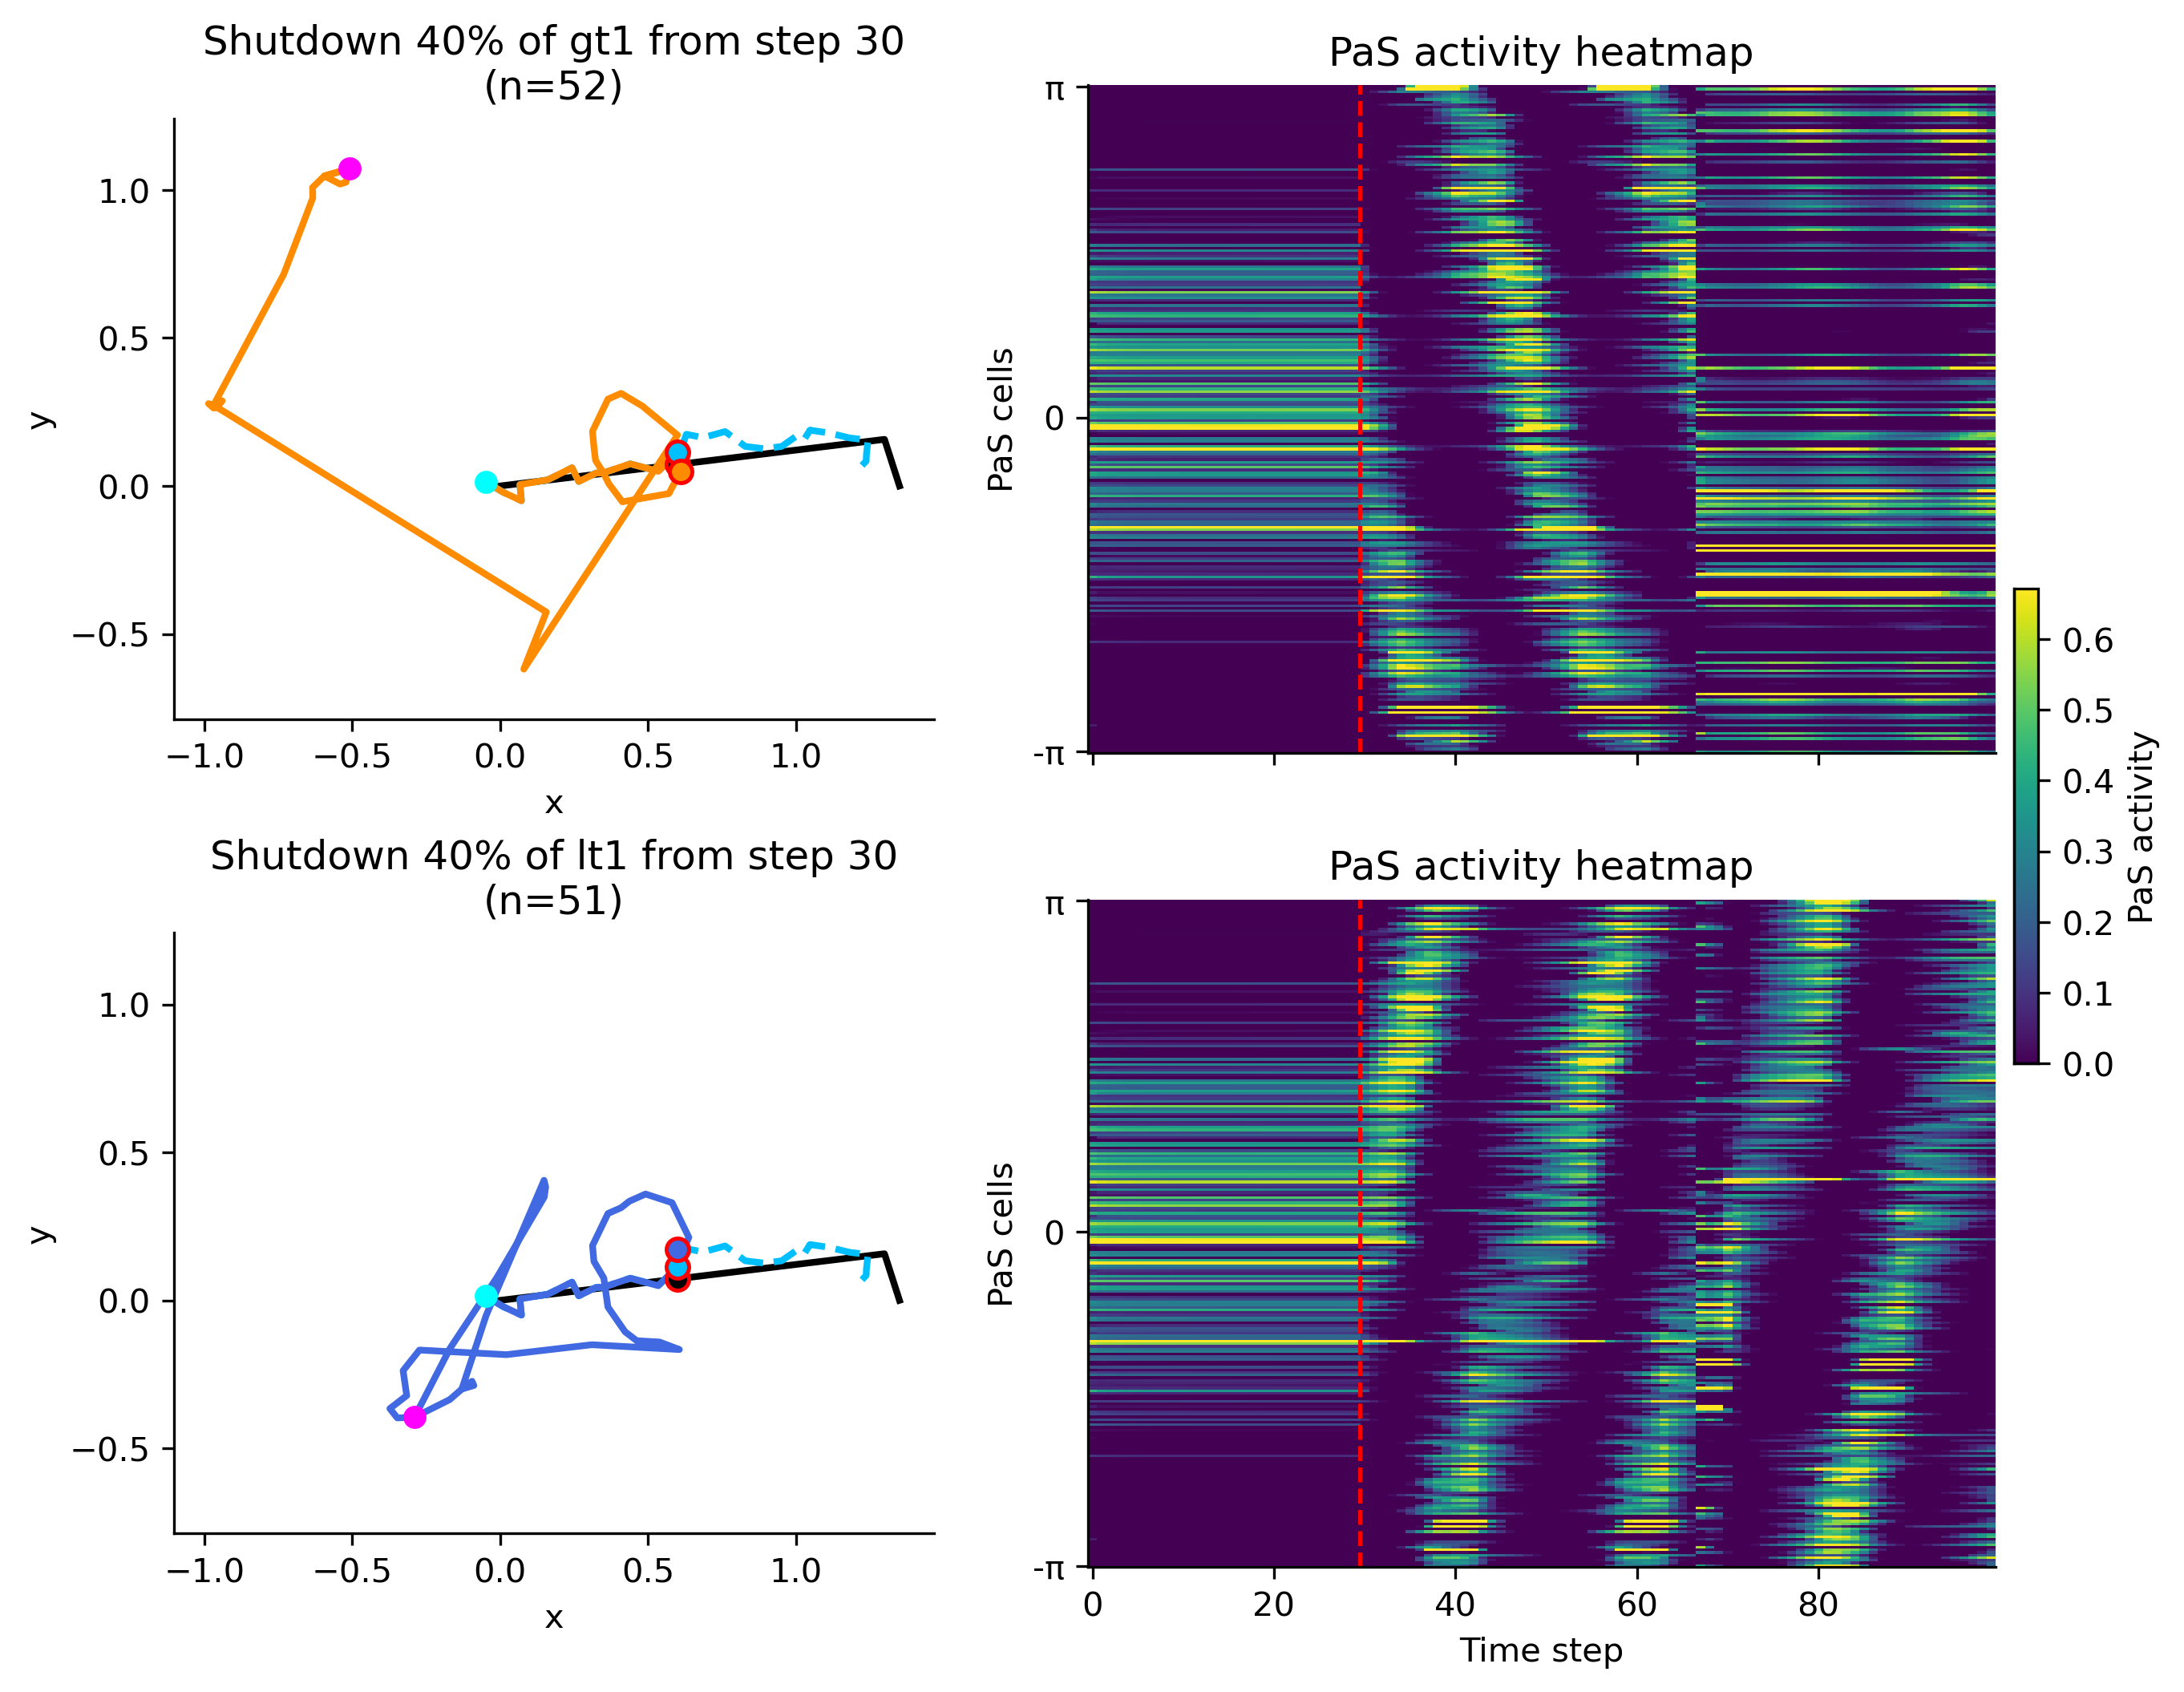

In [5]:
from trajectory_generator_seed import TrajectoryGenerator

# --------------------------------------------------
# reproducible seeds
# --------------------------------------------------
traj_seed = 456
shutdown_seed = 12

# --------------------------------------------------
# Parameters
# --------------------------------------------------
smooth_win = 0  # Even number: 3/5/7/...

options.sequence_length = 100
shutdown_frac = 0.4  # Shutdown Fraction of Shifters
shutdown_start = 30  # start shutdown from this step

trajectory_generator_joint = TrajectoryGenerator(
    options,
    place_cells=place_cells,
    direction_cells=direction_cells,
    seed=traj_seed
)

rng = np.random.default_rng(shutdown_seed)


# --------------------------------------------------
# CCW / CW ratemaps
# --------------------------------------------------
# preferred direction order from all-condition ratemap
pref_bin = np.argmax(activations_lmn, axis=1)

# peak firing rate ratio
peak_ccw = np.max(activations_lmn_ccw, axis=1)
peak_cw  = np.max(activations_lmn_cw, axis=1)

eps = 1e-12
ratio = peak_ccw / (peak_cw + eps)

# groups
idx_gt1 = np.where(ratio > 1)[0]   # CCW/CW > 1
idx_lt1 = np.where(ratio < 1)[0]   # CCW/CW < 1

# sort each group by preferred direction
idx_gt1 = idx_gt1[np.argsort(pref_bin[idx_gt1])]
idx_lt1 = idx_lt1[np.argsort(pref_bin[idx_lt1])]

# --------------------------------------------------
# get same trajectory
# --------------------------------------------------
batch = trajectory_generator_joint.get_test_batch_straight()
ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos = unpack_batch(batch)

if s is None or init_actp is None or pos is None:
    raise ValueError(
        "Joint batch still not available. Make sure place_cells and direction_cells both exist."
    )

if isinstance(mdir, torch.Tensor):
    mdir_np = mdir.detach().cpu().numpy()
else:
    mdir_np = np.asarray(mdir)

if mdir_np.ndim == 3:
    mdir_np = mdir_np[..., 0]

if isinstance(pos, torch.Tensor):
    pos_np = pos.detach().cpu().numpy()
else:
    pos_np = np.asarray(pos)

angle_range = getattr(direction_cells, "angle_range", 2 * np.pi)

# --------------------------------------------------
# shutdown-from-step rollout: no block alternation, no reset
# --------------------------------------------------
def run_lmn_pas_mec_with_delayed_shutdown(
    model,
    inputs,
    shut_idx=None,
    shutdown_start=30,
):
    """
    LMN recurrent-output shutdown starts only from shutdown_start.
    Before that, normal rollout.
    No reset, no block logic.
    shut_idx: indices of LMN cells whose outgoing recurrent columns are zeroed.
    """
    s, init_actp, ang_v, init_dir_actv = inputs
    device = ang_v.device
    dtype = ang_v.dtype

    W_lmn_ih = model.LmnRNN.weight_ih_l0
    W_lmn_hh_full = model.LmnRNN.weight_hh_l0
    W_lmn_hh_shut = model.LmnRNN.weight_hh_l0.clone()
    lmn_act_fn = get_act_fn_from_name(model.LmnRNN.nonlinearity)

    W_pas_ih = model.PaSRNN.weight_ih_l0
    W_pas_hh = model.PaSRNN.weight_hh_l0
    pas_act_fn = get_act_fn_from_name(model.PaSRNN.nonlinearity)

    W_conj_ih = model.conjRNN.weight_ih_l0
    W_conj_hh = model.conjRNN.weight_hh_l0
    conj_act_fn = get_act_fn_from_name(model.conjRNN.nonlinearity)

    W_mec_ih = model.mECRNN.weight_ih_l0
    W_mec_hh = model.mECRNN.weight_hh_l0
    mec_act_fn = get_act_fn_from_name(model.mECRNN.nonlinearity)

    if shut_idx is not None and len(shut_idx) > 0:
        W_lmn_hh_shut[:, shut_idx] = 0.0

    h_lmn = model.LmnEncoder(init_dir_actv)
    h_pas = model.PaSEncoder(init_dir_actv)
    h_conj = model.conjEncoder(init_actp)
    h_mec = model.mECEncoder(init_actp)

    T, B, _ = ang_v.shape
    Nlmn = h_lmn.shape[1]
    Npas = h_pas.shape[1]
    Ncg  = h_conj.shape[1]
    Ng   = h_mec.shape[1]

    lmn_seq  = torch.zeros((T, B, Nlmn), device=device, dtype=dtype)
    pas_seq  = torch.zeros((T, B, Npas), device=device, dtype=dtype)
    conj_seq = torch.zeros((T, B, Ncg),  device=device, dtype=dtype)
    mec_seq  = torch.zeros((T, B, Ng),   device=device, dtype=dtype)

    for t in range(T):
        x_t = ang_v[t]
        s_t = s[t]

        W_lmn_hh_use = W_lmn_hh_full if t < shutdown_start else W_lmn_hh_shut

        h_lmn = lmn_act_fn(x_t @ W_lmn_ih.T + h_lmn @ W_lmn_hh_use.T)

        h_pas = pas_act_fn(h_lmn @ W_pas_ih.T + h_pas @ W_pas_hh.T)

        pas_t = model.PaSNorm(h_pas) if model.PaSNorm is not None else h_pas
        drive_in = torch.cat([s_t, pas_t], dim=-1)

        h_conj = conj_act_fn(drive_in @ W_conj_ih.T + h_conj @ W_conj_hh.T)

        h_mec = mec_act_fn(h_conj @ W_mec_ih.T + h_mec @ W_mec_hh.T)

        lmn_seq[t] = h_lmn
        pas_seq[t] = h_pas
        conj_seq[t] = h_conj
        mec_seq[t] = h_mec

    return lmn_seq, pas_seq, conj_seq, mec_seq

# --------------------------------------------------
# choose 40% shutdown cells for each group
# --------------------------------------------------
def choose_shutdown_cells(group_idx, shutdown_frac, rng):
    group_idx = np.asarray(group_idx, dtype=int)
    if len(group_idx) == 0 or shutdown_frac <= 0:
        return np.array([], dtype=int)

    n_shut = int(np.round(shutdown_frac * len(group_idx)))
    n_shut = max(1, n_shut)
    n_shut = min(n_shut, len(group_idx))
    return np.sort(rng.choice(group_idx, size=n_shut, replace=False))

shut_gt1 = choose_shutdown_cells(idx_gt1, shutdown_frac, rng)
shut_lt1 = choose_shutdown_cells(idx_lt1, shutdown_frac, rng)

print(f"Trajectory seed: {traj_seed}")
print(f"Shutdown seed: {shutdown_seed}")
print(f"Shutdown starts at step: {shutdown_start}")
print(f"Shutdown gt1 cells: {len(shut_gt1)} / {len(idx_gt1)}")
print(f"Shutdown lt1 cells: {len(shut_lt1)} / {len(idx_lt1)}")

# --------------------------------------------------
# run normal + two shutdown conditions on the SAME trajectory
# --------------------------------------------------
with torch.no_grad():
    # normal
    lmn_normal, pas_normal, conj_normal, mec_normal = run_lmn_pas_mec_with_delayed_shutdown(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        shut_idx=None,
        shutdown_start=shutdown_start,
    )
    mec_preds_normal = model.mECDecoder(mec_normal)
    pred_pos_normal = place_cells.get_nearest_cell_pos(mec_preds_normal).detach().cpu().numpy()

    # row 1: shutdown 40% of gt1 from step 30
    lmn_gt1, pas_gt1, conj_gt1, mec_gt1 = run_lmn_pas_mec_with_delayed_shutdown(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        shut_idx=shut_gt1,
        shutdown_start=shutdown_start,
    )
    mec_preds_gt1 = model.mECDecoder(mec_gt1)
    pred_pos_gt1 = place_cells.get_nearest_cell_pos(mec_preds_gt1).detach().cpu().numpy()

    # row 2: shutdown 40% of lt1 from step 30
    lmn_lt1, pas_lt1, conj_lt1, mec_lt1 = run_lmn_pas_mec_with_delayed_shutdown(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        shut_idx=shut_lt1,
        shutdown_start=shutdown_start,
    )
    mec_preds_lt1 = model.mECDecoder(mec_lt1)
    pred_pos_lt1 = place_cells.get_nearest_cell_pos(mec_preds_lt1).detach().cpu().numpy()

# --------------------------------------------------
# prepare XY trajectories
# rotate by true trajectory so x-axis is along true movement
# --------------------------------------------------
true_xy = pos_np[:, 0, :]
pred_xy_normal = pred_pos_normal[:, 0, :]
pred_xy_gt1 = pred_pos_gt1[:, 0, :]
pred_xy_lt1 = pred_pos_lt1[:, 0, :]

true_xy_rot, pred_xy_normal_rot, rot_theta = rotate_xy_to_horizontal(true_xy, pred_xy_normal)

origin = true_xy[0].copy()
c = np.cos(-rot_theta)
s_ = np.sin(-rot_theta)
R = np.array([[c, -s_],
              [s_,  c]])

pred_xy_gt1_rot = (pred_xy_gt1 - origin) @ R.T
pred_xy_lt1_rot = (pred_xy_lt1 - origin) @ R.T

# --------------------------------------------------
# prepare PaS heatmaps
# same style as previous heatmap, but NO overlay lines
# --------------------------------------------------
pref_idx_pas = np.argmax(activations_pas, axis=1)
n_angle_bins = activations_pas.shape[1]

order_pas = np.argsort(pref_idx_pas)
pref_sorted = pref_idx_pas[order_pas]

true_ang_0 = np.mod(mdir_np[:, 0], 2 * np.pi)
true_bin = np.floor(true_ang_0 / (2 * np.pi) * n_angle_bins).astype(int)
true_bin = np.clip(true_bin, 0, n_angle_bins - 1)

def build_centered_pas_heatmap(pas_tensor, order_pas, pref_sorted, true_bin, smooth_win=0):
    pas_np = pas_tensor.detach().cpu().numpy()   # [T, B, Npas]
    pas_heat = pas_np[:, 0, order_pas].T         # [Npas, T]

    n_cells = pas_heat.shape[0]
    center_row = n_cells // 2

    pas_heat_centered = np.empty_like(pas_heat)
    for tt in range(pas_heat.shape[1]):
        diffs = np.abs(pref_sorted - true_bin[tt])
        diffs = np.minimum(diffs, n_angle_bins - diffs)
        target_row = np.argmin(diffs)
        shift = center_row - target_row
        pas_heat_centered[:, tt] = np.roll(pas_heat[:, tt], shift)

    if smooth_win > 1:
        pas_heat_centered = smooth_columns_boxcar(pas_heat_centered, win=smooth_win)

    # Normalize Heatmap
    col_max = np.max(np.abs(pas_heat_centered), axis=0, keepdims=True)
    col_max[col_max == 0] = 1.0
    pas_heat_centered = pas_heat_centered / col_max

    return pas_heat_centered

pas_heat_gt1 = build_centered_pas_heatmap(
    pas_gt1, order_pas, pref_sorted, true_bin, smooth_win=smooth_win
)
pas_heat_lt1 = build_centered_pas_heatmap(
    pas_lt1, order_pas, pref_sorted, true_bin, smooth_win=smooth_win
)

# shared color scale for both heatmaps
all_heat = np.concatenate([pas_heat_gt1.ravel(), pas_heat_lt1.ravel()])
vmin_pas = np.percentile(all_heat, 2)
vmax_pas = np.percentile(all_heat, 98)

# --------------------------------------------------
# plot 2x2 figure
# col 1 = trajectory
# col 2 = heatmap
# row 1 = gt1 shutdown
# row 2 = lt1 shutdown
# --------------------------------------------------
fig, axes = plt.subplots(
    2, 2,
    figsize=(10, 8),
    dpi=300,
    gridspec_kw={'width_ratios': [1.0, 1.25], 'wspace': 0.18, 'hspace': 0.22}
)

# ---------- row 1, col 1: gt1 trajectory ----------
ax = axes[0, 0]
ax.plot(
    true_xy_rot[:, 0], true_xy_rot[:, 1],
    color='black', linewidth=2, label='True trajectory'
)
ax.plot(
    pred_xy_normal_rot[:, 0], pred_xy_normal_rot[:, 1],
    color='deepskyblue', linewidth=2, linestyle='--', label='Normal model'
)
ax.plot(
    pred_xy_gt1_rot[:, 0], pred_xy_gt1_rot[:, 1],
    color='darkorange', linewidth=2, label='Shutdown model'
)

ax.scatter(true_xy_rot[shutdown_start, 0], true_xy_rot[shutdown_start, 1],
           color='red', s=45, zorder=6, label='Shutdown start')
ax.axvline if False else None  # no-op, just to keep nothing else changed

ax.scatter(pred_xy_gt1_rot[0, 0], pred_xy_gt1_rot[0, 1], color='cyan', s=35, zorder=5, label='Start')
ax.scatter(pred_xy_gt1_rot[-1, 0], pred_xy_gt1_rot[-1, 1], color='magenta', s=35, zorder=5, label='End')
ax.set_aspect('equal', adjustable='box')
ax.set_title(f"Shutdown 40% of gt1 from step {shutdown_start}\n(n={len(shut_gt1)})")
ax.set_xlabel('x')
ax.set_ylabel('y')
#ax.legend(loc='best', fontsize=8)

# mark shutdown start on all three trajectories
for xy, color in [
    (true_xy_rot, 'black'),
    (pred_xy_normal_rot, 'deepskyblue'),
    (pred_xy_gt1_rot, 'darkorange'),
]:
    ax.scatter(xy[shutdown_start, 0], xy[shutdown_start, 1],
               color=color, edgecolors='red', linewidths=1.2, s=45, zorder=6)

# ---------- row 1, col 2: gt1 heatmap ----------
ax = axes[0, 1]
im = ax.imshow(
    pas_heat_gt1,
    aspect='auto',
    origin='lower',
    interpolation='nearest',
    extent=[-0.5, pas_heat_gt1.shape[1] - 0.5, -0.5, pas_heat_gt1.shape[0] - 0.5],
    vmin=vmin_pas,
    vmax=vmax_pas,
)
ax.axvline(shutdown_start - 0.5, color='red', linestyle='--', linewidth=1.2)
ax.set_title("PaS activity heatmap")
ax.set_ylabel('PaS cells')
ax.set_yticks([0, pas_heat_gt1.shape[0] // 2, pas_heat_gt1.shape[0] - 1])
ax.set_yticklabels(['-π', '0', 'π'])
ax.set_xticklabels([])

# ---------- row 2, col 1: lt1 trajectory ----------
ax = axes[1, 0]
ax.plot(
    true_xy_rot[:, 0], true_xy_rot[:, 1],
    color='black', linewidth=2, label='True trajectory'
)
ax.plot(
    pred_xy_normal_rot[:, 0], pred_xy_normal_rot[:, 1],
    color='deepskyblue', linewidth=2, linestyle='--', label='Normal model'
)
ax.plot(
    pred_xy_lt1_rot[:, 0], pred_xy_lt1_rot[:, 1],
    color='royalblue', linewidth=2, label='Shutdown model'
)

for xy, color in [
    (true_xy_rot, 'black'),
    (pred_xy_normal_rot, 'deepskyblue'),
    (pred_xy_lt1_rot, 'royalblue'),
]:
    ax.scatter(xy[shutdown_start, 0], xy[shutdown_start, 1],
               color=color, edgecolors='red', linewidths=1.2, s=45, zorder=6)

ax.scatter(pred_xy_lt1_rot[0, 0], pred_xy_lt1_rot[0, 1], color='cyan', s=35, zorder=5, label='Start')
ax.scatter(pred_xy_lt1_rot[-1, 0], pred_xy_lt1_rot[-1, 1], color='magenta', s=35, zorder=5, label='End')
ax.set_aspect('equal', adjustable='box')
ax.set_title(f"Shutdown 40% of lt1 from step {shutdown_start}\n(n={len(shut_lt1)})")
ax.set_xlabel('x')
ax.set_ylabel('y')
#ax.legend(loc='best', fontsize=8)

# ---------- row 2, col 2: lt1 heatmap ----------
ax = axes[1, 1]
im = ax.imshow(
    pas_heat_lt1,
    aspect='auto',
    origin='lower',
    interpolation='nearest',
    extent=[-0.5, pas_heat_lt1.shape[1] - 0.5, -0.5, pas_heat_lt1.shape[0] - 0.5],
    vmin=vmin_pas,
    vmax=vmax_pas,
)
ax.axvline(shutdown_start - 0.5, color='red', linestyle='--', linewidth=1.2)
ax.set_title("PaS activity heatmap")
ax.set_xlabel('Time step')
ax.set_ylabel('PaS cells')
ax.set_yticks([0, pas_heat_lt1.shape[0] // 2, pas_heat_lt1.shape[0] - 1])
ax.set_yticklabels(['-π', '0', 'π'])

# ---------- match trajectory axis limits across rows ----------
traj_all = np.vstack([true_xy_rot, pred_xy_normal_rot, pred_xy_gt1_rot, pred_xy_lt1_rot])
xmin, ymin = np.min(traj_all, axis=0)
xmax, ymax = np.max(traj_all, axis=0)
xpad = 0.05 * max(xmax - xmin, 1e-6)
ypad = 0.10 * max(ymax - ymin, 1e-6)

for ax in [axes[0, 0], axes[1, 0]]:
    ax.set_xlim(xmin - xpad, xmax + xpad)
    ax.set_ylim(ymin - ypad, ymax + ypad)

# ---------- one shared colorbar for heatmaps ----------
cbar = fig.colorbar(im, ax=[axes[0, 1], axes[1, 1]], fraction=0.025, pad=0.02)
cbar.set_label('PaS activity')

sns.despine()
fig.tight_layout()
plt.show()

### Paper figure: knocking out AHV+ or AHV- and check the bump activity

Trajectory seed: 12
Shutdown seed: 330
Shutdown starts at step: 30
Shutdown CCW-dominant cells: 64 / 129
Shutdown CW-dominant cells: 64 / 127


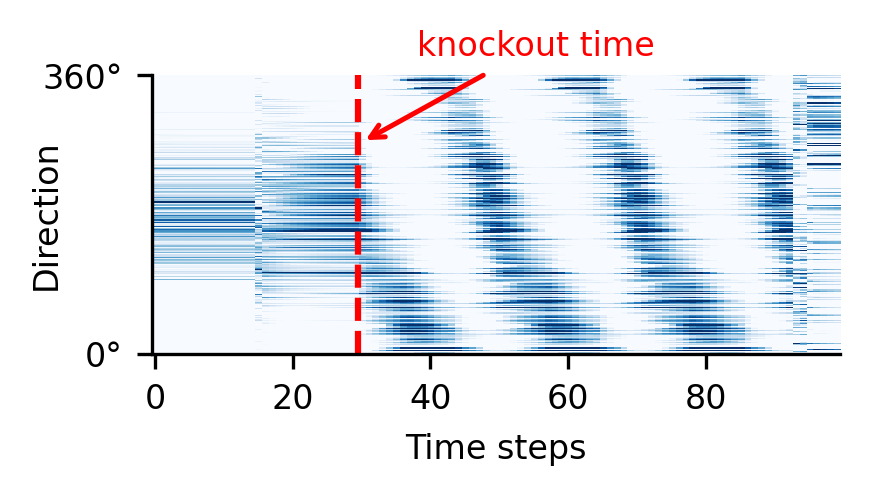

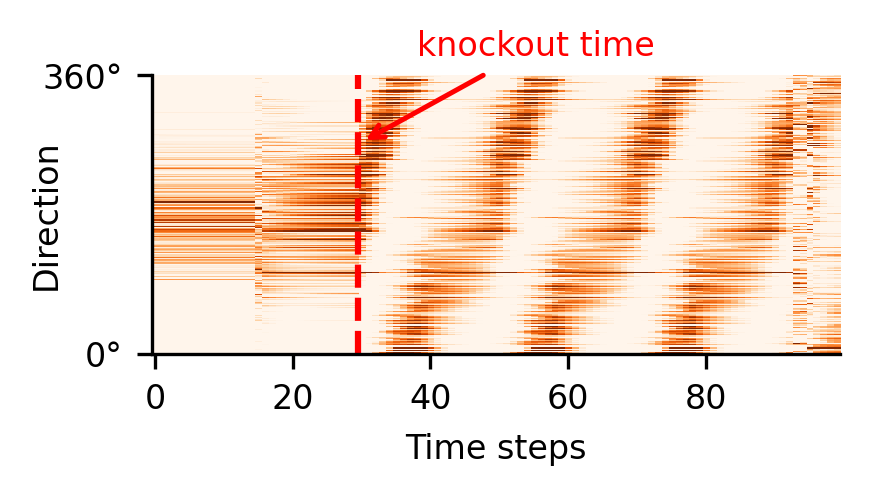

In [6]:
from trajectory_generator_seed import TrajectoryGenerator
from scipy.ndimage import gaussian_filter1d

# --------------------------------------------------
# reproducible seeds
# --------------------------------------------------
traj_seed = 12
shutdown_seed = 330

# --------------------------------------------------
# parameters
# --------------------------------------------------
smooth_win = 0
options.sequence_length = 100

shutdown_frac = 0.5
shutdown_start = 30

trajectory_generator_joint = TrajectoryGenerator(
    options,
    place_cells=place_cells,
    direction_cells=direction_cells,
    seed=traj_seed,
)

rng = np.random.default_rng(shutdown_seed)


# --------------------------------------------------
# classify LMN cells by CCW/CW peak ratio
# --------------------------------------------------
pref_bin_lmn = np.argmax(activations_lmn, axis=1)

peak_ccw = np.max(activations_lmn_ccw, axis=1)
peak_cw = np.max(activations_lmn_cw, axis=1)

eps = 1e-12
ccw_cw_ratio = peak_ccw / (peak_cw + eps)

idx_ccw_dom = np.where(ccw_cw_ratio > 1)[0]
idx_cw_dom = np.where(ccw_cw_ratio < 1)[0]

idx_ccw_dom = idx_ccw_dom[np.argsort(pref_bin_lmn[idx_ccw_dom])]
idx_cw_dom = idx_cw_dom[np.argsort(pref_bin_lmn[idx_cw_dom])]


def choose_shutdown_cells(group_idx, shutdown_frac, rng):
    group_idx = np.asarray(group_idx, dtype=int)

    if len(group_idx) == 0 or shutdown_frac <= 0:
        return np.array([], dtype=int)

    n_shut = int(np.round(shutdown_frac * len(group_idx)))
    n_shut = np.clip(n_shut, 1, len(group_idx))

    return np.sort(rng.choice(group_idx, size=n_shut, replace=False))


shut_ccw_dom = choose_shutdown_cells(idx_ccw_dom, shutdown_frac, rng)
shut_cw_dom = choose_shutdown_cells(idx_cw_dom, shutdown_frac, rng)

print(f"Trajectory seed: {traj_seed}")
print(f"Shutdown seed: {shutdown_seed}")
print(f"Shutdown starts at step: {shutdown_start}")
print(f"Shutdown CCW-dominant cells: {len(shut_ccw_dom)} / {len(idx_ccw_dom)}")
print(f"Shutdown CW-dominant cells: {len(shut_cw_dom)} / {len(idx_cw_dom)}")


# --------------------------------------------------
# get one straight trajectory
# --------------------------------------------------
batch = trajectory_generator_joint.get_test_batch_straight()
ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos = unpack_batch(batch)

if s is None or init_actp is None:
    raise ValueError(
        "Joint batch is not available. Make sure place_cells and direction_cells both exist."
    )

mdir_np = mdir.detach().cpu().numpy() if isinstance(mdir, torch.Tensor) else np.asarray(mdir)

if mdir_np.ndim == 3:
    mdir_np = mdir_np[..., 0]


# --------------------------------------------------
# LMN shutdown rollout
# --------------------------------------------------
def run_lmn_pas_mec_with_delayed_shutdown(
    model,
    inputs,
    shut_idx=None,
    shutdown_start=30,
):
    """
    Zero selected LMN recurrent outputs from shutdown_start onward.
    Returns LMN, PaS, Conj, and mEC activity sequences.
    """
    s, init_actp, ang_v, init_dir_actv = inputs

    device = ang_v.device
    dtype = ang_v.dtype

    W_lmn_ih = model.LmnRNN.weight_ih_l0
    W_lmn_hh_full = model.LmnRNN.weight_hh_l0
    W_lmn_hh_shut = model.LmnRNN.weight_hh_l0.clone()

    if shut_idx is not None and len(shut_idx) > 0:
        W_lmn_hh_shut[:, shut_idx] = 0.0

    lmn_act_fn = get_act_fn_from_name(model.LmnRNN.nonlinearity)

    W_pas_ih = model.PaSRNN.weight_ih_l0
    W_pas_hh = model.PaSRNN.weight_hh_l0
    pas_act_fn = get_act_fn_from_name(model.PaSRNN.nonlinearity)

    W_conj_ih = model.conjRNN.weight_ih_l0
    W_conj_hh = model.conjRNN.weight_hh_l0
    conj_act_fn = get_act_fn_from_name(model.conjRNN.nonlinearity)

    W_mec_ih = model.mECRNN.weight_ih_l0
    W_mec_hh = model.mECRNN.weight_hh_l0
    mec_act_fn = get_act_fn_from_name(model.mECRNN.nonlinearity)

    h_lmn = model.LmnEncoder(init_dir_actv)
    h_pas = model.PaSEncoder(init_dir_actv)
    h_conj = model.conjEncoder(init_actp)
    h_mec = model.mECEncoder(init_actp)

    T, B, _ = ang_v.shape
    Nlmn = h_lmn.shape[1]
    Npas = h_pas.shape[1]
    Ncg = h_conj.shape[1]
    Ng = h_mec.shape[1]

    lmn_seq = torch.zeros((T, B, Nlmn), device=device, dtype=dtype)
    pas_seq = torch.zeros((T, B, Npas), device=device, dtype=dtype)
    conj_seq = torch.zeros((T, B, Ncg), device=device, dtype=dtype)
    mec_seq = torch.zeros((T, B, Ng), device=device, dtype=dtype)

    for t in range(T):
        W_lmn_hh_use = W_lmn_hh_full if t < shutdown_start else W_lmn_hh_shut

        h_lmn = lmn_act_fn(ang_v[t] @ W_lmn_ih.T + h_lmn @ W_lmn_hh_use.T)

        h_pas = pas_act_fn(h_lmn @ W_pas_ih.T + h_pas @ W_pas_hh.T)

        pas_t = model.PaSNorm(h_pas) if model.PaSNorm is not None else h_pas
        drive_in = torch.cat([s[t], pas_t], dim=-1)

        h_conj = conj_act_fn(drive_in @ W_conj_ih.T + h_conj @ W_conj_hh.T)

        h_mec = mec_act_fn(h_conj @ W_mec_ih.T + h_mec @ W_mec_hh.T)

        lmn_seq[t] = h_lmn
        pas_seq[t] = h_pas
        conj_seq[t] = h_conj
        mec_seq[t] = h_mec

    return lmn_seq, pas_seq, conj_seq, mec_seq


with torch.no_grad():
    lmn_ccw, pas_ccw, conj_ccw, mec_ccw = run_lmn_pas_mec_with_delayed_shutdown(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        shut_idx=shut_ccw_dom,
        shutdown_start=shutdown_start,
    )

    lmn_cw, pas_cw, conj_cw, mec_cw = run_lmn_pas_mec_with_delayed_shutdown(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        shut_idx=shut_cw_dom,
        shutdown_start=shutdown_start,
    )


# --------------------------------------------------
# centered PaS heatmaps
# --------------------------------------------------
pref_idx_pas = np.argmax(activations_pas, axis=1)
n_angle_bins = activations_pas.shape[1]

order_pas = np.argsort(pref_idx_pas)
pref_sorted = pref_idx_pas[order_pas]

true_ang = np.mod(mdir_np[:, 0], 2 * np.pi)
true_bin = np.floor(true_ang / (2 * np.pi) * n_angle_bins).astype(int)
true_bin = np.clip(true_bin, 0, n_angle_bins - 1)


def build_centered_pas_heatmap(
    pas_tensor,
    order_pas,
    pref_sorted,
    true_bin,
    smooth_win=0,
):
    pas_np = pas_tensor.detach().cpu().numpy()
    pas_heat = pas_np[:, 0, order_pas].T

    n_cells, n_time = pas_heat.shape
    center_row = n_cells // 2

    pas_heat_centered = np.empty_like(pas_heat)

    for t in range(n_time):
        diffs = np.abs(pref_sorted - true_bin[t])
        diffs = np.minimum(diffs, n_angle_bins - diffs)

        target_row = np.argmin(diffs)
        shift = center_row - target_row

        pas_heat_centered[:, t] = np.roll(pas_heat[:, t], shift)

    if smooth_win > 1:
        pas_heat_centered = smooth_columns_boxcar(pas_heat_centered, win=smooth_win)

    col_max = np.max(np.abs(pas_heat_centered), axis=0, keepdims=True)
    col_max[col_max == 0] = 1.0

    return pas_heat_centered / col_max


pas_heat_ccw = build_centered_pas_heatmap(
    pas_ccw,
    order_pas,
    pref_sorted,
    true_bin,
    smooth_win=smooth_win,
)

pas_heat_cw = build_centered_pas_heatmap(
    pas_cw,
    order_pas,
    pref_sorted,
    true_bin,
    smooth_win=smooth_win,
)

all_heat = np.concatenate([pas_heat_ccw.ravel(), pas_heat_cw.ravel()])
vmin_pas = np.percentile(all_heat, 2)
vmax_pas = np.percentile(all_heat, 98)


# --------------------------------------------------
# plotting helper
# --------------------------------------------------
def plot_pas_shutdown_heatmap(
    pas_heat,
    title,
    shutdown_start,
    vmin,
    vmax,
    cmap
):
    fig, ax = plt.subplots(figsize=(3, 1.8), dpi=300)

    # pas_heat_plot = gaussian_filter1d(
    #     pas_heat,
    #     sigma=5,
    #     axis=0,
    #     mode='wrap'
    # )

    im = ax.imshow(
        pas_heat,
        aspect='auto',
        origin='lower',
        interpolation='none',
        extent=[-0.5, pas_heat.shape[1] - 0.5, -0.5, pas_heat.shape[0] - 0.5],
        vmin=vmin,
        vmax=vmax,
        cmap=cmap,
    )

    ax.axvline(
        shutdown_start - 0.5,
        color='red',
        linestyle='--',
        linewidth=1.5,
    )

    ax.annotate(
        'knockout time',
        xy=(shutdown_start - 0.5, pas_heat.shape[0] * 0.75),
        xytext=(shutdown_start + 8, pas_heat.shape[0] * 1.1),
        color='red',
        fontsize=8,
        ha='left',
        va='center',
        arrowprops=dict(
            arrowstyle='->',
            color='red',
            linewidth=1.2,
        ),
    )

    # ax.set_title(title, fontsize=10)
    ax.set_xlabel('Time steps', fontsize=8)
    ax.set_ylabel('Direction', fontsize=8, labelpad=-5)
    ax.set_yticks([0, pas_heat.shape[0] - 1])
    ax.set_yticklabels(['0°', '360°'])
    ax.tick_params(axis='both', which='major', labelsize=8)

    # cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
    # cbar.set_label('PaS activity')

    sns.despine()
    fig.tight_layout()
    # plt.savefig(f"./docs/{title.replace(' ', '_')}_pas_heatmap.pdf")


plot_pas_shutdown_heatmap(
    pas_heat_ccw,
    title=f"Knockout AHV+ cells (n={len(shut_ccw_dom)})",
    shutdown_start=shutdown_start,
    vmin=vmin_pas,
    vmax=vmax_pas,
    cmap='Blues'
)

plot_pas_shutdown_heatmap(
    pas_heat_cw,
    title=f"Knockout AHV- cells (n={len(shut_cw_dom)})",
    shutdown_start=shutdown_start,
    vmin=vmin_pas,
    vmax=vmax_pas,
    cmap='Oranges'
)

Trajectory seed: 12
Shutdown seed: 331
Shutdown starts at step: 30
Shutdown gt1 cells: 129 / 129
Shutdown lt1 cells: 127 / 127


/tmp/ipykernel_518759/456158583.py:448: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


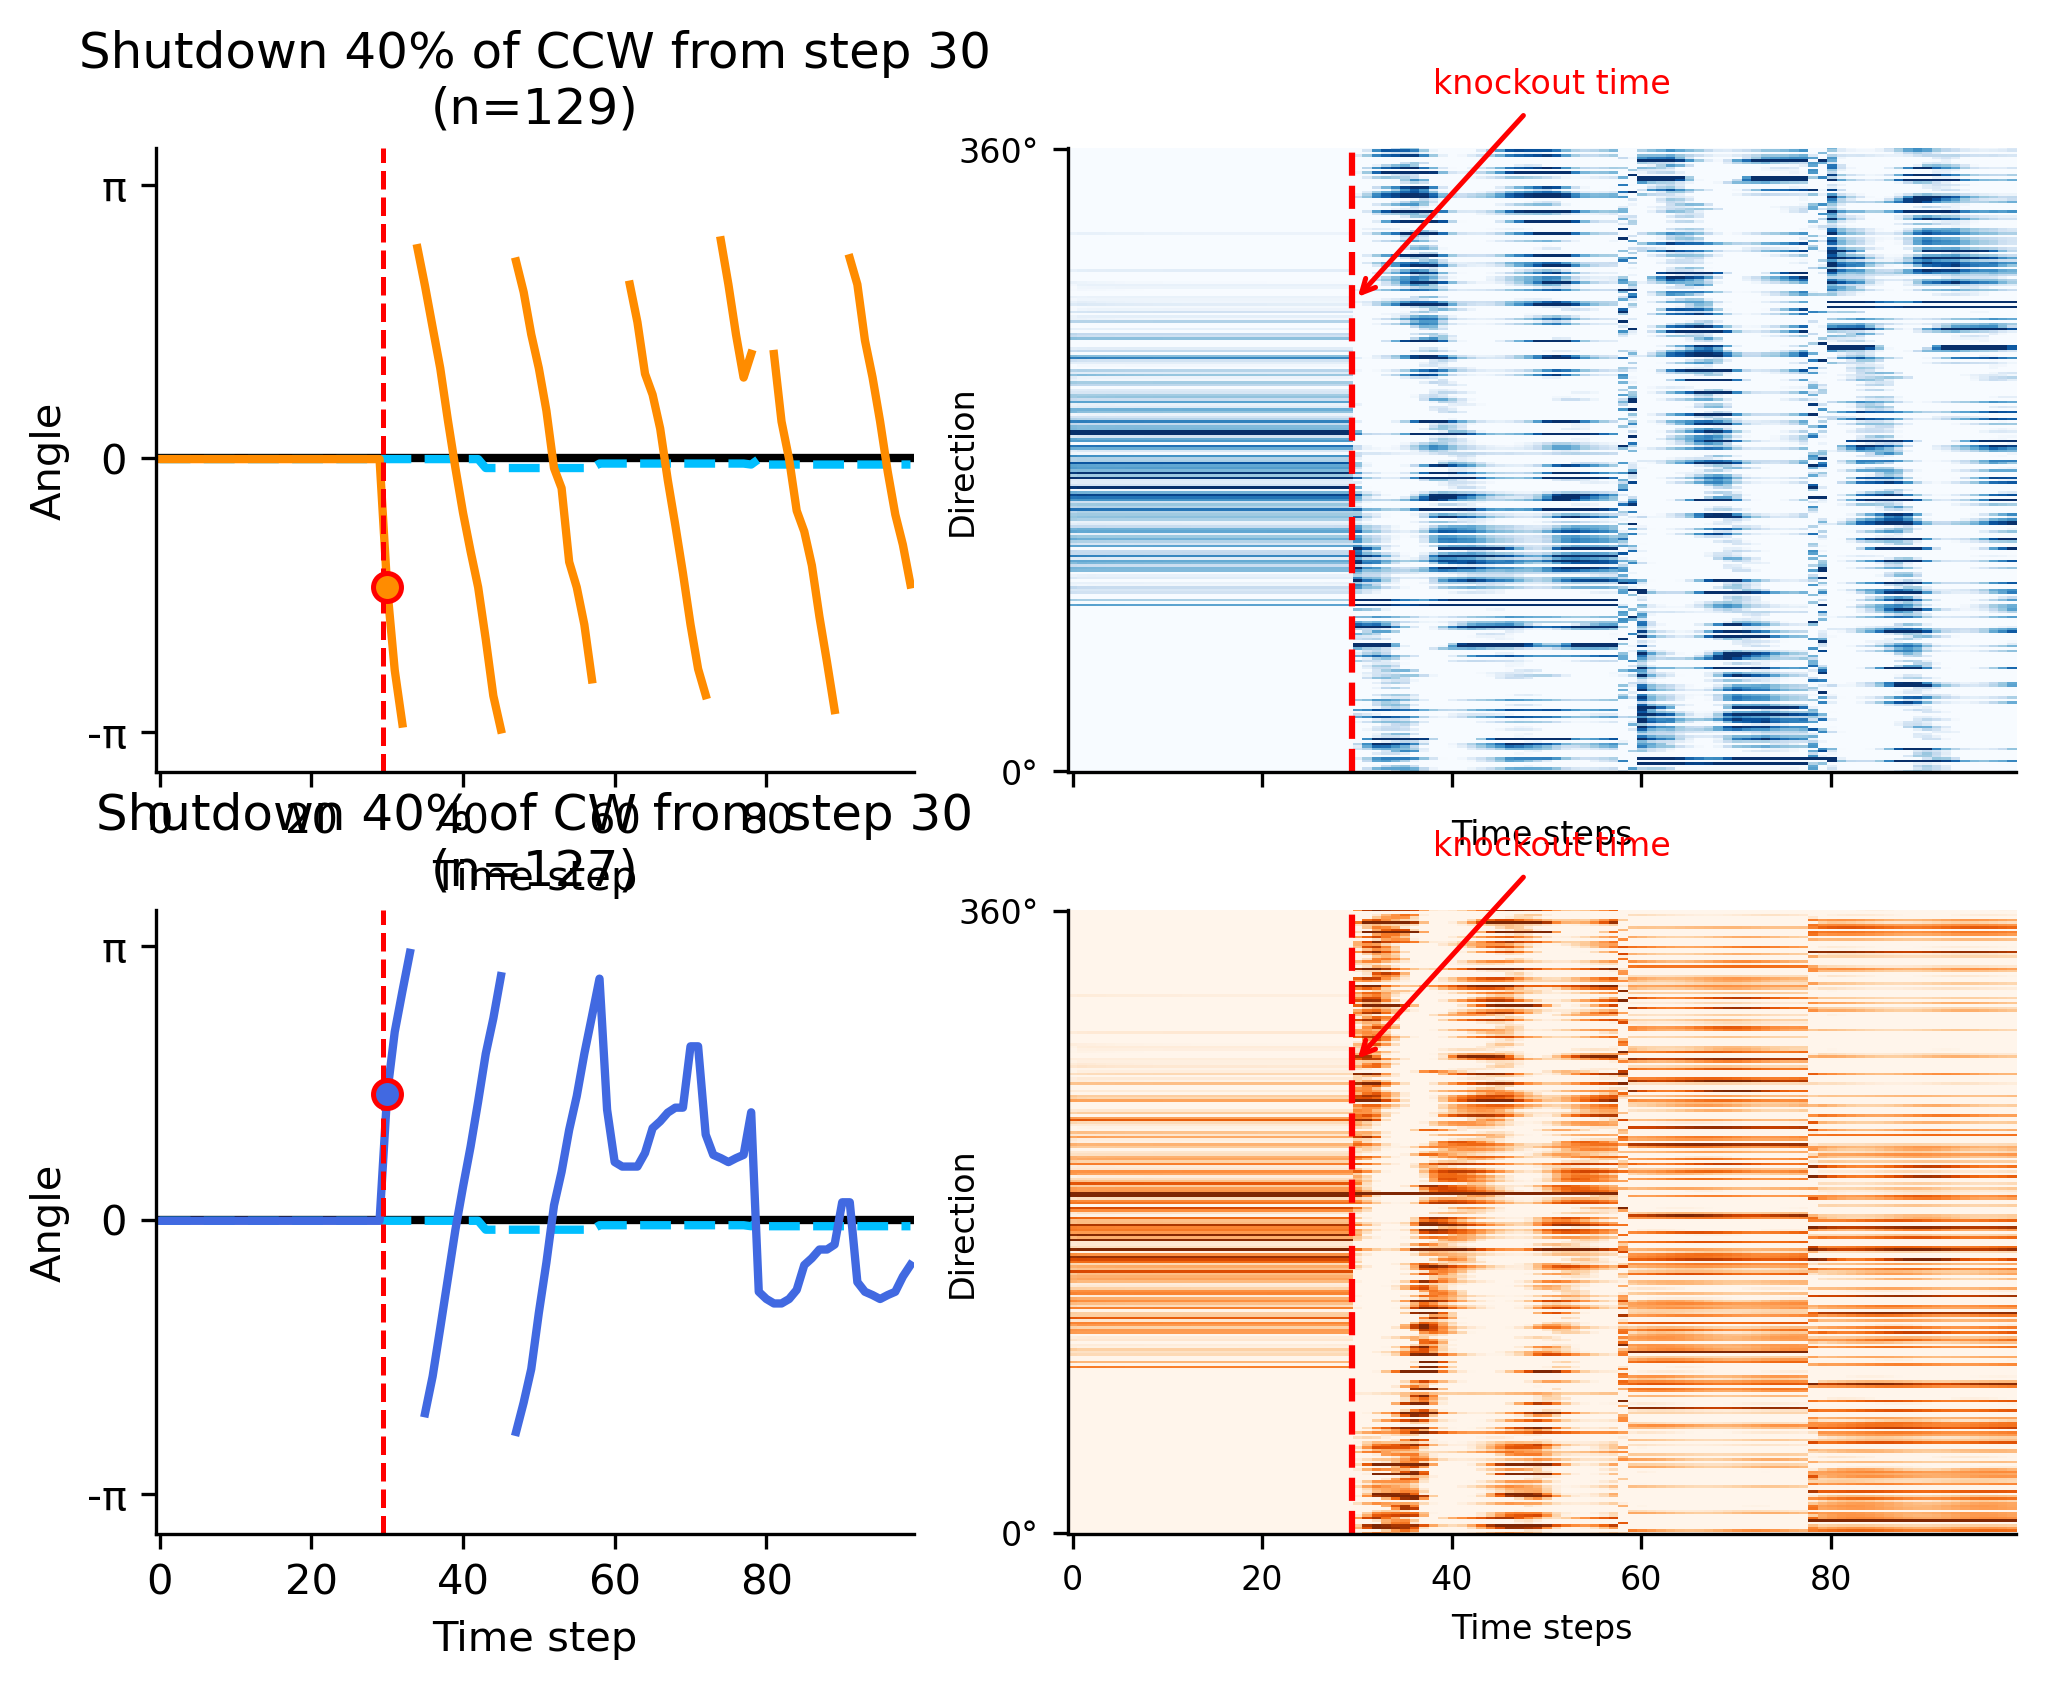

In [7]:
from trajectory_generator_seed import TrajectoryGenerator
from scipy.ndimage import gaussian_filter1d

# --------------------------------------------------
# reproducible seeds
# --------------------------------------------------
traj_seed = 12
shutdown_seed = 331

# --------------------------------------------------
# Parameters
# --------------------------------------------------
smooth_win = 0
options.sequence_length = 100
shutdown_frac = 1  # Shutdown Fraction of Shifters
shutdown_start = 30  # start shutdown from this step

trajectory_generator_joint = TrajectoryGenerator(
    options,
    place_cells=place_cells,
    direction_cells=direction_cells,
    seed=traj_seed,
)

rng = np.random.default_rng(shutdown_seed)

# --------------------------------------------------
# get same trajectory
# --------------------------------------------------
trajectory_generator_joint.set_seed(traj_seed)
batch = trajectory_generator_joint.get_test_batch_straight()
ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos = unpack_batch(batch)

if s is None or init_actp is None or pos is None:
    raise ValueError(
        "Joint batch still not available. Make sure place_cells and direction_cells both exist."
    )

if isinstance(mdir, torch.Tensor):
    mdir_np = mdir.detach().cpu().numpy()
else:
    mdir_np = np.asarray(mdir)

if mdir_np.ndim == 3:
    mdir_np = mdir_np[..., 0]

if isinstance(pos, torch.Tensor):
    pos_np = pos.detach().cpu().numpy()
else:
    pos_np = np.asarray(pos)

angle_range = getattr(direction_cells, "angle_range", 2 * np.pi)

# --------------------------------------------------
# helpers
# --------------------------------------------------
def break_at_wrap(angle_series, wrap=np.pi):
    a = np.asarray(angle_series).squeeze()
    out = a.astype(float).copy()
    jumps = np.abs(np.diff(out))
    out[1:][jumps > wrap] = np.nan
    return out

def wrap_to_pi(x):
    return (x + np.pi) % (2 * np.pi) - np.pi

def smooth_columns_boxcar(arr, win=5):
    arr = np.asarray(arr, dtype=float)
    if win <= 1:
        return arr.copy()
    if win % 2 == 0:
        raise ValueError("win must be odd.")

    kernel = np.ones(win, dtype=float) / win
    pad = win // 2

    out = np.empty_like(arr, dtype=float)
    for j in range(arr.shape[1]):
        col = arr[:, j]
        col_pad = np.pad(col, pad_width=pad, mode='edge')
        out[:, j] = np.convolve(col_pad, kernel, mode='valid')
    return out

# --------------------------------------------------
# shutdown-from-step rollout: no block alternation, no reset
# --------------------------------------------------
def run_lmn_pas_mec_with_delayed_shutdown(
    model,
    inputs,
    shut_idx=None,
    shutdown_start=30,
):
    """
    LMN recurrent-output shutdown starts only from shutdown_start.
    Before that, normal rollout.
    No reset, no block logic.
    shut_idx: indices of LMN cells whose outgoing recurrent columns are zeroed.
    """
    s, init_actp, ang_v, init_dir_actv = inputs
    device = ang_v.device
    dtype = ang_v.dtype

    W_lmn_ih = model.LmnRNN.weight_ih_l0
    W_lmn_hh_full = model.LmnRNN.weight_hh_l0
    W_lmn_hh_shut = model.LmnRNN.weight_hh_l0.clone()
    lmn_act_fn = get_act_fn_from_name(model.LmnRNN.nonlinearity)

    W_pas_ih = model.PaSRNN.weight_ih_l0
    W_pas_hh = model.PaSRNN.weight_hh_l0
    pas_act_fn = get_act_fn_from_name(model.PaSRNN.nonlinearity)

    W_conj_ih = model.conjRNN.weight_ih_l0
    W_conj_hh = model.conjRNN.weight_hh_l0
    conj_act_fn = get_act_fn_from_name(model.conjRNN.nonlinearity)

    W_mec_ih = model.mECRNN.weight_ih_l0
    W_mec_hh = model.mECRNN.weight_hh_l0
    mec_act_fn = get_act_fn_from_name(model.mECRNN.nonlinearity)

    if shut_idx is not None and len(shut_idx) > 0:
        W_lmn_hh_shut[:, shut_idx] = 0.0

    h_lmn = model.LmnEncoder(init_dir_actv)
    h_pas = model.PaSEncoder(init_dir_actv)
    h_conj = model.conjEncoder(init_actp)
    h_mec = model.mECEncoder(init_actp)

    T, B, _ = ang_v.shape
    Nlmn = h_lmn.shape[1]
    Npas = h_pas.shape[1]
    Ncg  = h_conj.shape[1]
    Ng   = h_mec.shape[1]

    lmn_seq  = torch.zeros((T, B, Nlmn), device=device, dtype=dtype)
    pas_seq  = torch.zeros((T, B, Npas), device=device, dtype=dtype)
    conj_seq = torch.zeros((T, B, Ncg),  device=device, dtype=dtype)
    mec_seq  = torch.zeros((T, B, Ng),   device=device, dtype=dtype)

    for t in range(T):
        x_t = ang_v[t]
        s_t = s[t]

        W_lmn_hh_use = W_lmn_hh_full if t < shutdown_start else W_lmn_hh_shut

        h_lmn = lmn_act_fn(x_t @ W_lmn_ih.T + h_lmn @ W_lmn_hh_use.T)

        h_pas = pas_act_fn(h_lmn @ W_pas_ih.T + h_pas @ W_pas_hh.T)

        pas_t = model.PaSNorm(h_pas) if model.PaSNorm is not None else h_pas
        drive_in = torch.cat([s_t, pas_t], dim=-1)

        h_conj = conj_act_fn(drive_in @ W_conj_ih.T + h_conj @ W_conj_hh.T)

        h_mec = mec_act_fn(h_conj @ W_mec_ih.T + h_mec @ W_mec_hh.T)

        lmn_seq[t] = h_lmn
        pas_seq[t] = h_pas
        conj_seq[t] = h_conj
        mec_seq[t] = h_mec

    return lmn_seq, pas_seq, conj_seq, mec_seq

# --------------------------------------------------
# choose 40% shutdown cells for each group
# --------------------------------------------------
def choose_shutdown_cells(group_idx, shutdown_frac, rng):
    group_idx = np.asarray(group_idx, dtype=int)
    if len(group_idx) == 0 or shutdown_frac <= 0:
        return np.array([], dtype=int)

    n_shut = int(np.round(shutdown_frac * len(group_idx)))
    n_shut = max(1, n_shut)
    n_shut = min(n_shut, len(group_idx))
    return np.sort(rng.choice(group_idx, size=n_shut, replace=False))

shut_gt1 = choose_shutdown_cells(idx_gt1, shutdown_frac, rng)
shut_lt1 = choose_shutdown_cells(idx_lt1, shutdown_frac, rng)

print(f"Trajectory seed: {traj_seed}")
print(f"Shutdown seed: {shutdown_seed}")
print(f"Shutdown starts at step: {shutdown_start}")
print(f"Shutdown gt1 cells: {len(shut_gt1)} / {len(idx_gt1)}")
print(f"Shutdown lt1 cells: {len(shut_lt1)} / {len(idx_lt1)}")

# --------------------------------------------------
# run normal + two shutdown conditions on the SAME trajectory
# --------------------------------------------------
with torch.no_grad():
    # normal
    lmn_normal, pas_normal, conj_normal, mec_normal = run_lmn_pas_mec_with_delayed_shutdown(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        shut_idx=None,
        shutdown_start=shutdown_start,
    )
    pas_preds_normal = model.PaSDecoder(pas_normal)
    pred_ang_normal = direction_cells.get_nearest_cell_dir(pas_preds_normal).detach().cpu().numpy()

    # row 1: shutdown 40% of gt1 from step 30
    lmn_gt1, pas_gt1, conj_gt1, mec_gt1 = run_lmn_pas_mec_with_delayed_shutdown(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        shut_idx=shut_gt1,
        shutdown_start=shutdown_start,
    )
    pas_preds_gt1 = model.PaSDecoder(pas_gt1)
    pred_ang_gt1 = direction_cells.get_nearest_cell_dir(pas_preds_gt1).detach().cpu().numpy()

    # row 2: shutdown 40% of lt1 from step 30
    lmn_lt1, pas_lt1, conj_lt1, mec_lt1 = run_lmn_pas_mec_with_delayed_shutdown(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        shut_idx=shut_lt1,
        shutdown_start=shutdown_start,
    )
    pas_preds_lt1 = model.PaSDecoder(pas_lt1)
    pred_ang_lt1 = direction_cells.get_nearest_cell_dir(pas_preds_lt1).detach().cpu().numpy()

# make angular outputs 2D [T, B]
if pred_ang_normal.ndim == 3 and pred_ang_normal.shape[-1] == 1:
    pred_ang_normal = pred_ang_normal[..., 0]
if pred_ang_gt1.ndim == 3 and pred_ang_gt1.shape[-1] == 1:
    pred_ang_gt1 = pred_ang_gt1[..., 0]
if pred_ang_lt1.ndim == 3 and pred_ang_lt1.shape[-1] == 1:
    pred_ang_lt1 = pred_ang_lt1[..., 0]

# --------------------------------------------------
# prepare angular trajectories from PaS
# --------------------------------------------------
t = np.arange(mdir_np.shape[0])

true_plot = wrap_to_pi(mdir_np)
pred_normal_plot = wrap_to_pi(pred_ang_normal)
pred_gt1_plot = wrap_to_pi(pred_ang_gt1)
pred_lt1_plot = wrap_to_pi(pred_ang_lt1)

center_shift = true_plot[:, [0]]
true_centered = wrap_to_pi(true_plot - center_shift)
pred_normal_centered = wrap_to_pi(pred_normal_plot - center_shift)
pred_gt1_centered = wrap_to_pi(pred_gt1_plot - center_shift)
pred_lt1_centered = wrap_to_pi(pred_lt1_plot - center_shift)

true_line = break_at_wrap(true_centered[:, 0])
pred_normal_line = break_at_wrap(pred_normal_centered[:, 0])
pred_gt1_line = break_at_wrap(pred_gt1_centered[:, 0])
pred_lt1_line = break_at_wrap(pred_lt1_centered[:, 0])

# --------------------------------------------------
# prepare PaS heatmaps
# updated heatmap style only
# --------------------------------------------------
pref_idx_pas = np.argmax(activations_pas, axis=1)
n_angle_bins = activations_pas.shape[1]

order_pas = np.argsort(pref_idx_pas)
pref_sorted = pref_idx_pas[order_pas]

true_ang_0 = np.mod(mdir_np[:, 0], 2 * np.pi)
true_bin = np.floor(true_ang_0 / (2 * np.pi) * n_angle_bins).astype(int)
true_bin = np.clip(true_bin, 0, n_angle_bins - 1)

def build_centered_pas_heatmap(pas_tensor, order_pas, pref_sorted, true_bin, smooth_win=0):
    pas_np = pas_tensor.detach().cpu().numpy()   # [T, B, Npas]
    pas_heat = pas_np[:, 0, order_pas].T         # [Npas, T]

    n_cells = pas_heat.shape[0]
    center_row = n_cells // 2

    pas_heat_centered = np.empty_like(pas_heat)
    for tt in range(pas_heat.shape[1]):
        diffs = np.abs(pref_sorted - true_bin[tt])
        diffs = np.minimum(diffs, n_angle_bins - diffs)
        target_row = np.argmin(diffs)
        shift = center_row - target_row
        pas_heat_centered[:, tt] = np.roll(pas_heat[:, tt], shift)

    if smooth_win > 1:
        pas_heat_centered = smooth_columns_boxcar(pas_heat_centered, win=smooth_win)

    # Normalize Heatmap
    col_max = np.max(np.abs(pas_heat_centered), axis=0, keepdims=True)
    col_max[col_max == 0] = 1.0
    pas_heat_centered = pas_heat_centered / col_max

    return pas_heat_centered

pas_heat_gt1 = build_centered_pas_heatmap(
    pas_gt1, order_pas, pref_sorted, true_bin, smooth_win=smooth_win
)
pas_heat_lt1 = build_centered_pas_heatmap(
    pas_lt1, order_pas, pref_sorted, true_bin, smooth_win=smooth_win
)

# shared color scale for both heatmaps
all_heat = np.concatenate([pas_heat_gt1.ravel(), pas_heat_lt1.ravel()])
vmin_pas = np.percentile(all_heat, 2)
vmax_pas = np.percentile(all_heat, 98)

# --------------------------------------------------
# plot 2x2 figure
# col 1 = angular trajectory from PaS
# col 2 = heatmap
# row 1 = gt1 shutdown
# row 2 = lt1 shutdown
# --------------------------------------------------
fig, axes = plt.subplots(
    2, 2,
    figsize=(8, 6),
    dpi=300,
    gridspec_kw={'width_ratios': [1.0, 1.25], 'wspace': 0.18, 'hspace': 0.22}
)

# ---------- row 1, col 1: gt1 angular trajectory ----------
ax = axes[0, 0]
ax.plot(
    t, true_line,
    color='black', linewidth=2, label='True trajectory'
)
ax.plot(
    t, pred_normal_line,
    color='deepskyblue', linewidth=2, linestyle='--', label='Normal model'
)
ax.plot(
    t, pred_gt1_line,
    color='darkorange', linewidth=2, label='Shutdown model'
)
ax.axvline(shutdown_start - 0.5, color='red', linestyle='--', linewidth=1.2, label='Shutdown start')
ax.scatter(shutdown_start, pred_gt1_line[shutdown_start], color='darkorange',
           edgecolors='red', linewidths=1.2, s=45, zorder=6)
ax.set_title(f"Shutdown 40% of CCW from step {shutdown_start}\n(n={len(shut_gt1)})")
ax.set_xlabel('Time step')
ax.set_ylabel('Angle')
ax.set_yticks([-np.pi, 0, np.pi])
ax.set_yticklabels(['-π', '0', 'π'])
#ax.legend(loc='best', fontsize=8)

# ---------- row 1, col 2: gt1 heatmap ----------
ax = axes[0, 1]
im1 = ax.imshow(
    pas_heat_gt1,
    aspect='auto',
    origin='lower',
    interpolation='none',
    extent=[-0.5, pas_heat_gt1.shape[1] - 0.5, -0.5, pas_heat_gt1.shape[0] - 0.5],
    vmin=vmin_pas,
    vmax=vmax_pas,
    cmap='Blues',
)
ax.axvline(
    shutdown_start - 0.5,
    color='red',
    linestyle='--',
    linewidth=1.5,
)
ax.annotate(
    'knockout time',
    xy=(shutdown_start - 0.5, pas_heat_gt1.shape[0] * 0.75),
    xytext=(shutdown_start + 8, pas_heat_gt1.shape[0] * 1.1),
    color='red',
    fontsize=8,
    ha='left',
    va='center',
    arrowprops=dict(
        arrowstyle='->',
        color='red',
        linewidth=1.2,
    ),
)
ax.set_xlabel('Time steps', fontsize=8)
ax.set_ylabel('Direction', fontsize=8, labelpad=-5)
ax.set_yticks([0, pas_heat_gt1.shape[0] - 1])
ax.set_yticklabels(['0°', '360°'])
ax.tick_params(axis='both', which='major', labelsize=8)
ax.set_xticklabels([])

# ---------- row 2, col 1: lt1 angular trajectory ----------
ax = axes[1, 0]
ax.plot(
    t, true_line,
    color='black', linewidth=2, label='True trajectory'
)
ax.plot(
    t, pred_normal_line,
    color='deepskyblue', linewidth=2, linestyle='--', label='Normal model'
)
ax.plot(
    t, pred_lt1_line,
    color='royalblue', linewidth=2, label='Shutdown model'
)
ax.axvline(shutdown_start - 0.5, color='red', linestyle='--', linewidth=1.2, label='Shutdown start')
ax.scatter(shutdown_start, pred_lt1_line[shutdown_start], color='royalblue',
           edgecolors='red', linewidths=1.2, s=45, zorder=6)
ax.set_title(f"Shutdown 40% of CW from step {shutdown_start}\n(n={len(shut_lt1)})")
ax.set_xlabel('Time step')
ax.set_ylabel('Angle')
ax.set_yticks([-np.pi, 0, np.pi])
ax.set_yticklabels(['-π', '0', 'π'])
#ax.legend(loc='best', fontsize=8)

# ---------- row 2, col 2: lt1 heatmap ----------
ax = axes[1, 1]
im2 = ax.imshow(
    pas_heat_lt1,
    aspect='auto',
    origin='lower',
    interpolation='none',
    extent=[-0.5, pas_heat_lt1.shape[1] - 0.5, -0.5, pas_heat_lt1.shape[0] - 0.5],
    vmin=vmin_pas,
    vmax=vmax_pas,
    cmap='Oranges',
)
ax.axvline(
    shutdown_start - 0.5,
    color='red',
    linestyle='--',
    linewidth=1.5,
)
ax.annotate(
    'knockout time',
    xy=(shutdown_start - 0.5, pas_heat_lt1.shape[0] * 0.75),
    xytext=(shutdown_start + 8, pas_heat_lt1.shape[0] * 1.1),
    color='red',
    fontsize=8,
    ha='left',
    va='center',
    arrowprops=dict(
        arrowstyle='->',
        color='red',
        linewidth=1.2,
    ),
)
ax.set_xlabel('Time steps', fontsize=8)
ax.set_ylabel('Direction', fontsize=8, labelpad=-5)
ax.set_yticks([0, pas_heat_lt1.shape[0] - 1])
ax.set_yticklabels(['0°', '360°'])
ax.tick_params(axis='both', which='major', labelsize=8)

# ---------- match angular trajectory axis limits across rows ----------
ymin = min(np.nanmin(true_line), np.nanmin(pred_normal_line), np.nanmin(pred_gt1_line), np.nanmin(pred_lt1_line))
ymax = max(np.nanmax(true_line), np.nanmax(pred_normal_line), np.nanmax(pred_gt1_line), np.nanmax(pred_lt1_line))
ypad = 0.08 * max(ymax - ymin, 1e-6)

for ax in [axes[0, 0], axes[1, 0]]:
    ax.set_xlim(-0.5, len(t) - 0.5)
    ax.set_ylim(ymin - ypad, ymax + ypad)

sns.despine()
fig.tight_layout()
plt.show()

##  2. LR theta sweeps via Mutual Inhibition

###  PaS LR Sweeps + Population Activity Heatmap + mEC LR Sweeps + Session-Averaged

In [8]:
#Calculate PV Template First
# --------------------------------------------------
# build empirical tables first
# --------------------------------------------------

# how many normal batches to use to build empirical PaS encoder
n_encoder_batches = 50

# how many normal batches to build MEC spatial template table
n_mec_decoder_batches = 80
mec_x_bins = 25
mec_y_bins = 25

from trajectory_generator_seed import TrajectoryGenerator
traj_seed = 49
trajectory_generator_joint = TrajectoryGenerator(
    options,
    place_cells=place_cells,
    direction_cells=direction_cells,
    seed=traj_seed,
)


pas_state_table, pas_state_count = build_empirical_pas_state_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    direction_cells=direction_cells,
    n_batches=n_encoder_batches
)
print("Built empirical PaS state table.")
print(f"Min samples per direction bin: {pas_state_count.min()}")
print(f"Max samples per direction bin: {pas_state_count.max()}")

conj_template_table = build_empirical_conj_template_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    x_bins=mec_x_bins,
    y_bins=mec_y_bins,
    n_batches=n_mec_decoder_batches,
)
print("Built empirical Conj hidden-state template table.")
print(f"Min samples per spatial bin: {conj_template_table['counts'].min()}")
print(f"Max samples per spatial bin: {conj_template_table['counts'].max()}")


mec_template_table = build_empirical_mec_template_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    x_bins=mec_x_bins,
    y_bins=mec_y_bins,
    n_batches=n_mec_decoder_batches,
)
print("Built empirical MEC hidden-state template table.")
print(f"Min samples per spatial bin: {mec_template_table['counts'].min()}")
print(f"Max samples per spatial bin: {mec_template_table['counts'].max()}")


Built empirical PaS state table.
Min samples per direction bin: 354
Max samples per direction bin: 35075
Built empirical Conj hidden-state template table.
Min samples per spatial bin: 176
Max samples per spatial bin: 7100
Built empirical MEC hidden-state template table.
Min samples per spatial bin: 207
Max samples per spatial bin: 7195


### Make a paper figure about the directional sweeps

n idx_gt1 = 129
n idx_lt1 = 127


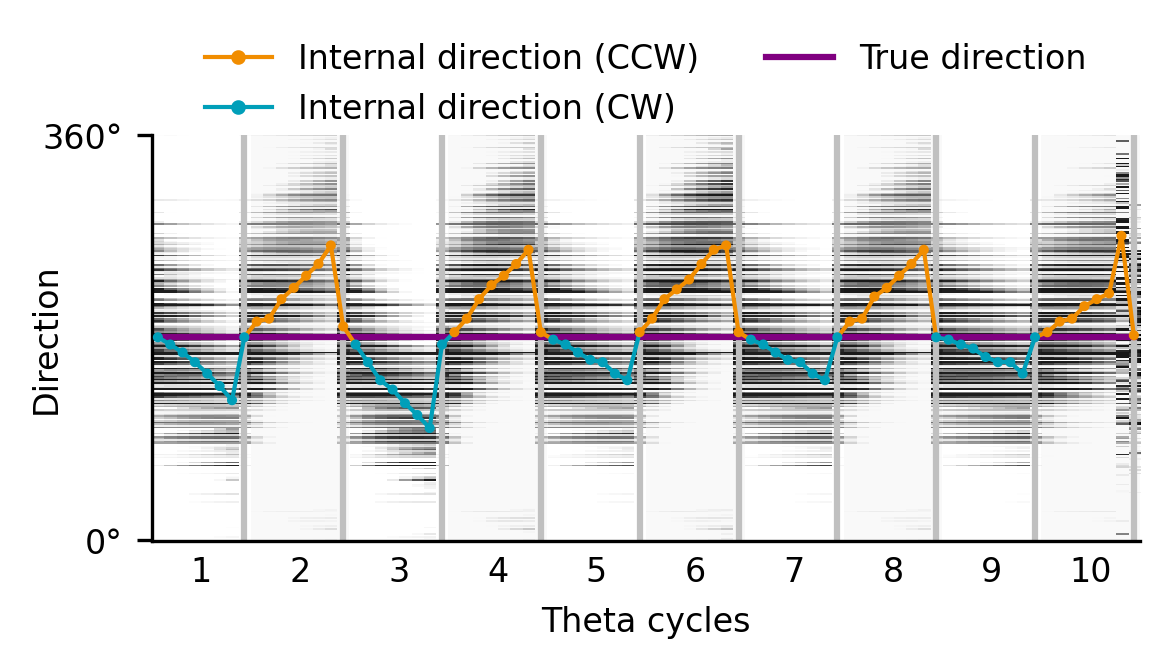

In [9]:
# Grid Cell Sweep - PV reset + model decoder
# 1) build session-averaged Conj and mEC hidden-state templates for each spatial bin from NORMAL dynamics
# 2) use those templates to RESET manipulated Conj and mEC hidden activity at reset steps
# 3) use MODEL mEC decoder for readout
# 4) keep Figure 1 = direction + heatmap, Figure 2 = XY trajectory
# 5) add NORMAL model rollout mEC trajectory to Figure 2
# 6) mark and label every reset point on manipulated decoded trajectory in Figure 2


import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from matplotlib.gridspec import GridSpec
from trajectory_generator_seed import TrajectoryGenerator
from matplotlib.collections import LineCollection

#Random Seeds
#seed_traj = 331
seed_traj=331
seed_shutdown = 407
seed_torch = 7

reset_point='last'
# --------------------------------------------------
# settings
# --------------------------------------------------
options.sequence_length = 80
options.batch_size = 20

block_len = 8
shutdown_frac = 0.2
dt = 0.02

# boxcar smoothing window for heatmap columns
smooth_win = 0   # odd integer, e.g. 3 / 5 / 7

rng = np.random.default_rng(seed_shutdown)
torch.manual_seed(seed_torch)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_torch)


options.use_place_cells = True
options.use_direction_cells = True


# --------------------------------------------------
# LMN groups from existing ratemaps
# --------------------------------------------------
pref_bin = np.argmax(activations_lmn, axis=1)

peak_ccw = np.max(activations_lmn_ccw, axis=1)
peak_cw  = np.max(activations_lmn_cw, axis=1)

eps = 1e-12
ratio = peak_ccw / (peak_cw + eps)

idx_gt1 = np.where(ratio > 1)[0]   # CCW/CW > 1
idx_lt1 = np.where(ratio < 1)[0]   # CCW/CW < 1

idx_gt1 = idx_gt1[np.argsort(pref_bin[idx_gt1])]
idx_lt1 = idx_lt1[np.argsort(pref_bin[idx_lt1])]

print(f"n idx_gt1 = {len(idx_gt1)}")
print(f"n idx_lt1 = {len(idx_lt1)}")


# --------------------------------------------------
# get same trajectory
# --------------------------------------------------
trajectory_generator_joint = TrajectoryGenerator(
    options,
    place_cells=place_cells,
    direction_cells=direction_cells,
    seed=seed_traj
)

batch = trajectory_generator_joint.get_test_batch_straight()
ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos = unpack_batch(batch)

if s is None or init_actp is None or pos is None:
    raise ValueError(
        "Joint batch still not available. Make sure place_cells and direction_cells both exist."
    )

if isinstance(mdir, torch.Tensor):
    mdir_np = mdir.detach().cpu().numpy()
else:
    mdir_np = np.asarray(mdir)

if mdir_np.ndim == 3:
    mdir_np = mdir_np[..., 0]

if isinstance(pos, torch.Tensor):
    pos_np = pos.detach().cpu().numpy()
else:
    pos_np = np.asarray(pos)

angle_range = getattr(direction_cells, "angle_range", 2 * np.pi)


# --------------------------------------------------
# build reset tables from NORMAL dynamics
# --------------------------------------------------
pas_state_table, pas_state_count = build_empirical_pas_state_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    direction_cells=direction_cells,
    n_batches=50,
)

conj_template_table = build_empirical_conj_template_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    x_bins=25,
    y_bins=25,
    n_batches=80,
)

mec_template_table = build_empirical_mec_template_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    x_bins=25,
    y_bins=25,
    n_batches=80,
)


# --------------------------------------------------
# run joint rollout with PV-template mEC reset
# --------------------------------------------------
with torch.no_grad():
    (
        lmn_block, pas_block, adap_block, conj_block, mec_block,
        shut_mask_record, source_blocks, shut_cells_per_block, reset_record
    ) = run_lmn_pas_conj_mec_with_blockwise_shutdown_and_joint_reset(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        dc_outputs=dc_outputs,
        mdir=mdir,
        pos=pos,
        pas_state_table=pas_state_table,
        conj_template_table=conj_template_table,
        mec_template_table=mec_template_table,
        idx_gt1=idx_gt1,
        idx_lt1=idx_lt1,
        block_len=block_len,
        shutdown_frac=shutdown_frac,
        rng=rng,
        reset_point=reset_point
    )

    pas_preds_block = model.PaSDecoder(pas_block)
    mec_preds_block = model.mECDecoder(mec_block)

# PaS decoding
pred_pas_block = direction_cells.get_nearest_cell_dir(pas_preds_block).detach().cpu().numpy()
if pred_pas_block.ndim == 3 and pred_pas_block.shape[-1] == 1:
    pred_pas_block = pred_pas_block[..., 0]

# MEC readout now uses MODEL decoder
pred_pos_block = place_cells.get_nearest_cell_pos(mec_preds_block).detach().cpu().numpy()


# --------------------------------------------------
# normal rollout for comparison in figure 2
# --------------------------------------------------
with torch.no_grad():
    (
        lmn_normal, pas_normal, adap_normal, conj_normal, mec_normal
    ) = run_normal_lmn_pas_conj_mec_rollout(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv)
    )

    mec_preds_normal = model.mECDecoder(mec_normal)

pred_pos_normal = place_cells.get_nearest_cell_pos(mec_preds_normal).detach().cpu().numpy()


# --------------------------------------------------
# plotting data
# --------------------------------------------------
true_plot = wrap_to_pi(mdir_np)
pred_pas_plot = wrap_to_pi(pred_pas_block)

t = np.arange(mdir_np.shape[0])

center_shift = true_plot[:, [0]]
true_centered = wrap_to_pi(true_plot - center_shift)
pred_pas_centered = wrap_to_pi(pred_pas_plot - center_shift)

true_line = break_at_wrap(true_centered[:, 0])
pred_pas_line = break_at_wrap(pred_pas_centered[:, 0])


# --------------------------------------------------
# PaS heatmap
# --------------------------------------------------
pas_np = pas_block.detach().cpu().numpy()

pref_idx_pas = np.argmax(activations_pas, axis=1)
n_angle_bins = activations_pas.shape[1]

order_pas = np.argsort(pref_idx_pas)
pref_sorted = pref_idx_pas[order_pas]

pas_heat = pas_np[:, 0, order_pas].T

true_ang_0 = np.mod(mdir_np[:, 0], 2 * np.pi)
true_bin = np.floor(true_ang_0 / (2 * np.pi) * n_angle_bins).astype(int)
true_bin = np.clip(true_bin, 0, n_angle_bins - 1)

n_cells = pas_heat.shape[0]
center_row = n_cells // 2

pas_heat_centered = np.empty_like(pas_heat)
for tt in range(pas_heat.shape[1]):
    diffs = np.abs(pref_sorted - true_bin[tt])
    diffs = np.minimum(diffs, n_angle_bins - diffs)
    target_row = np.argmin(diffs)
    shift = center_row - target_row
    pas_heat_centered[:, tt] = np.roll(pas_heat[:, tt], shift)

pas_heat = pas_heat_centered

if smooth_win > 1:
    pas_heat = smooth_columns_boxcar(pas_heat, win=smooth_win)

n_rows_pas = pas_heat.shape[0]
center_row_pas = n_rows_pas // 2

pred_rel = wrap_to_pi(pred_pas_plot[:, 0] - true_plot[:, 0])
pred_row = center_row_pas + pred_rel / (2 * np.pi) * n_rows_pas
true_row = np.full_like(pred_row, center_row_pas, dtype=float)

true_row_line = break_rows_at_jump(true_row, n_rows=n_rows_pas)
pred_row_line = break_rows_at_jump(pred_row, n_rows=n_rows_pas)


# --------------------------------------------------
# true / decoded XY trajectory for batch 0
# rotate so true trajectory is horizontal
# --------------------------------------------------
true_xy = pos_np[:, 0, :]
pred_xy = pred_pos_block[:, 0, :]
pred_xy_normal = pred_pos_normal[:, 0, :]

true_xy_rot, pred_xy_rot, rot_theta = rotate_xy_to_horizontal(true_xy, pred_xy)

# rotate normal decoded trajectory using SAME transform
origin = true_xy[0].copy()
pred_xy_normal_centered = pred_xy_normal - origin
c = np.cos(-rot_theta)
s = np.sin(-rot_theta)
R = np.array([[c, -s],
              [s,  c]])
pred_xy_normal_rot = pred_xy_normal_centered @ R.T

reset_steps = np.where(reset_record)[0]
reset_xy_rot = pred_xy_rot[reset_steps]


# --------------------------------------------------
# Figure 1: first two panels together
# --------------------------------------------------
fig1, axes1 = plt.subplots(figsize=(4, 2.5), dpi=300)

for start in range(0, len(t), block_len):
    end = min(start + block_len, len(t))
    block_idx = start // block_len
    shade_color = 'white' if block_idx % 2 == 0 else 'lightgrey'
    axes1.axvspan(start - 0.5, end - 0.5, alpha=0.12, color=shade_color, lw=0)

for rs in reset_steps:
    axes1.axvline(rs, color='silver', linestyle='-', linewidth=1.5, alpha=1)

# 2) PaS heatmap + overlay
vmin_pas = np.percentile(pas_heat, 2)
vmax_pas = np.percentile(pas_heat, 95)

im1 = axes1.imshow(
    pas_heat,
    aspect='auto',
    origin='lower',
    interpolation='nearest',
    extent=[-0.5, len(t) - 0.5, -0.5, pas_heat.shape[0] - 0.5],
    vmin=vmin_pas,
    vmax=vmax_pas,
    cmap='Greys'
)



# Internal direction: color by whether it is above or below true direction
valid = np.isfinite(pred_row_line) & np.isfinite(true_row_line)

points = np.array([t, pred_row_line]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

seg_valid = valid[:-1] & valid[1:]
seg_mid = 0.5 * (pred_row_line[:-1] + pred_row_line[1:])
true_mid = 0.5 * (true_row_line[:-1] + true_row_line[1:])

seg_colors = np.where(
    seg_mid >= true_mid,
    '#F18D00',   # above true direction
    '#009FB9',   # below true direction
)

lc_pred = LineCollection(
    segments[seg_valid],
    colors=seg_colors[seg_valid],
    linewidths=1,
    zorder=6,
)
axes1.add_collection(lc_pred)

# markers, colored pointwise by position relative to true direction
point_colors = np.where(
    pred_row_line >= true_row_line,
    '#F18D00',
    '#009FB9',
)

axes1.scatter(
    t[valid],
    pred_row_line[valid],
    c=point_colors[valid],
    s=2,
    zorder=7,
)

axes1.plot([], [], color='#F18D00', linewidth=1, marker='o', markersize=2.5, label='Internal direction (CCW)')
axes1.plot([], [], color='#009FB9', linewidth=1, marker='o', markersize=2.5, label='Internal direction (CW)')

axes1.plot(
    t, true_row_line,
    color='purple',
    linewidth=1.5,
    label='True direction',
    zorder=5
)


axes1.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.3),
    ncol=2,
    facecolor='white',
    frameon=False,
    fontsize=8,
)


axes1.set_ylabel('Direction', fontsize=8, labelpad=-5)
axes1.set_yticks([0, n_rows_pas - 1])
axes1.set_yticklabels(['0°', '360°'])
# x-axis as theta cycles
cycle_starts = np.arange(0, len(t), block_len)
cycle_centers = cycle_starts + (block_len - 1) / 2
cycle_labels = np.arange(1, len(cycle_starts) + 1)

axes1.set_xticks(cycle_centers)
axes1.set_xticklabels(cycle_labels)
axes1.set_xlabel('Theta cycles', fontsize=8)

axes1.tick_params(axis='x', which='major', labelsize=8, length=0)
axes1.tick_params(axis='y', which='major', labelsize=8)

#ticksize as 8


sns.despine()
fig1.tight_layout()

plt.savefig('./docs/directional_sweeps.pdf', format="pdf", dpi=300, bbox_inches="tight")

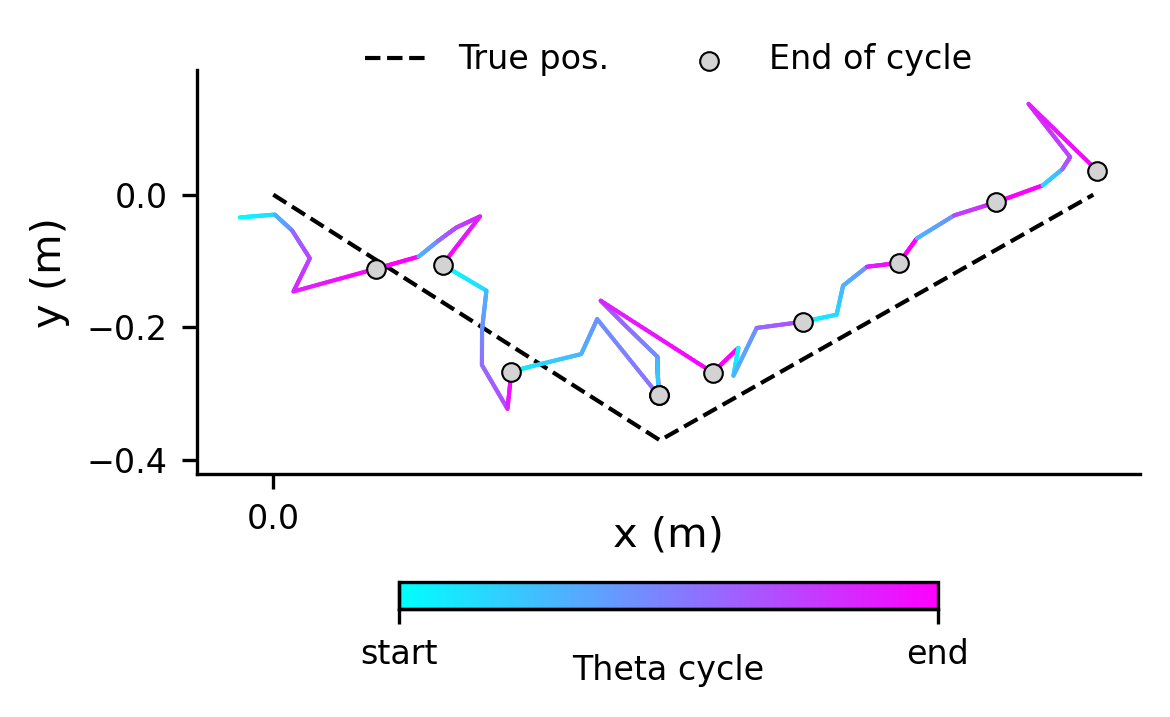

In [15]:


# --------------------------------------------------
# Figure 2: XY trajectory separate, with normal rollout
# --------------------------------------------------
from matplotlib.colors import Normalize
fig2, axes2 = plt.subplots(figsize=(4, 2.5), dpi=300)

axes2.plot(
    true_xy_rot[:, 0], true_xy_rot[:, 1],
    color='black',
    linewidth=1,
    linestyle='--',
    label='True pos.',
    zorder=2
)

lc = build_colored_line_by_block(
    axes2,
    pred_xy_rot,
    block_len=block_len,
    cmap='cool',
    lw=1,
    alpha=1.0,
    zorder=3,
    sub_per_step=30
)


axes2.scatter(
    reset_xy_rot[:, 0],
    reset_xy_rot[:, 1],
    s=20,
    facecolors='lightgray',
    edgecolors='black',
    linewidths=0.5,
    zorder=6,
    label='End of cycle'
)

# for k, rs in enumerate(reset_steps):
#     axes2.annotate(
#         f"{rs}",
#         (reset_xy_rot[k, 0], reset_xy_rot[k, 1]),
#         textcoords="offset points",
#         xytext=(4, 4),
#         fontsize=8,
#         color='red',
#         zorder=7
#     )

axes2.set_xlabel('x (m)', labelpad=-5)
axes2.set_ylabel('y (m)')
#axes2.set_title('Rotated XY trajectory: true vs manipulated decoded vs normal decoded')
axes2.set_aspect('auto', adjustable='box')
axes2.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.1),
    borderaxespad=0.,
    fontsize=8,
    ncol=2,
    frameon=False,
)

#xticks as 0, 1.5
axes2.set_xticks([0, 1.5])

all_xy = np.vstack([true_xy_rot, pred_xy_rot, pred_xy_normal_rot])
xmin, ymin = np.min(all_xy, axis=0)
xmax, ymax = np.max(all_xy, axis=0)
xpad = 0.05 * max(xmax - xmin, 1e-6)
ypad = 0.10 * max(ymax - ymin, 1e-6)
axes2.set_xlim(xmin - xpad, xmax + xpad)
axes2.set_ylim(ymin - ypad, ymax + ypad)
#tick size as 8
axes2.tick_params(axis='both', which='major', labelsize=8)


cbar2 = fig2.colorbar(
    lc,
    ax=axes2,
    orientation='horizontal',
    location='bottom',
    fraction=0.05,
    pad=0.20,
)
cbar2.set_ticks([0.0, 1.0])
cbar2.set_ticklabels(['start', 'end'], fontsize=8)
cbar2.set_label('Theta cycle', fontsize=8, labelpad=-4)


sns.despine()

plt.tight_layout()
plt.savefig('./docs/positional_sweeps.pdf', format="pdf", dpi=300, bbox_inches="tight")


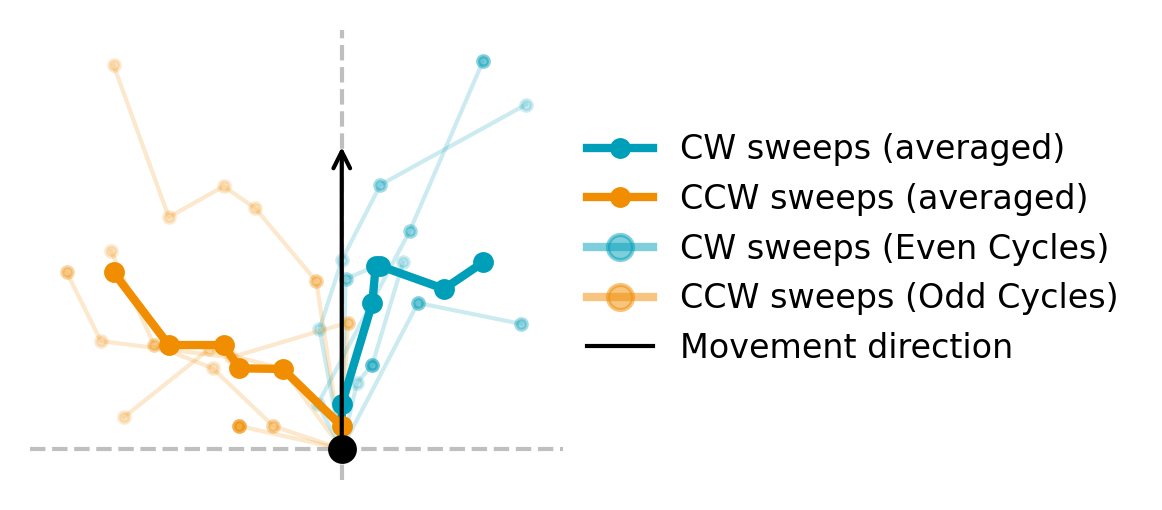

In [11]:


# --------------------------------------------------
# Figure 3: block-aligned trajectories
# - use points 0..block_len-1 in each block
# - exclude reset point
# - point 0 -> (0,0)
# - rotate by true direction at point 0 so it is vertical
# - show even/odd block medians
# --------------------------------------------------
# --------------------------------------------------
# Figure 3: overlapped version of 3a and 3b
# - all aligned blocks + pointwise medians on the same axis
# - 3a made more transparent
# --------------------------------------------------
aligned_blocks, block_ids, block_parity = build_aligned_block_trajectories(
    pred_xy=pred_xy,
    true_dir=mdir_np[:, 0],
    block_len=block_len
)

even_mask = (block_parity == 0)
odd_mask = (block_parity == 1)

aligned_even = aligned_blocks[even_mask]
aligned_odd = aligned_blocks[odd_mask]

median_even = pointwise_median_traj(aligned_even)
median_odd = pointwise_median_traj(aligned_odd)

fig3, ax3 = plt.subplots(1, 1, figsize=(4, 1.8), dpi=300)

# --------------------------------------------------
# first: plot all aligned blocks (old 3a), but more transparent
# --------------------------------------------------
for i, b in enumerate(block_ids):
    traj = aligned_blocks[i]
    color = '#009FB9' if (b % 2 == 0) else '#F18D00'

    ax3.plot(
        traj[:, 0], traj[:, 1],
        '-o',
        color=color,
        alpha=0.2,          # more transparent than before
        linewidth=1,
        markersize=2.5,
        zorder=1
    )

# --------------------------------------------------
# then: overlay medians (old 3b)
# --------------------------------------------------
if median_even is not None:
    ax3.plot(
        median_even[:, 0], median_even[:, 1],
        '-o',
        color='#009FB9',
        linewidth=2,
        markersize=4,
        label='CW sweeps (averaged)',
        zorder=4
    )


if median_odd is not None:
    ax3.plot(
        median_odd[:, 0], median_odd[:, 1],
        '-o',
        color='#F18D00',
        linewidth=2,
        markersize=4,
        label='CCW sweeps (averaged)',
        zorder=4
    )
    

# --------------------------------------------------
# origin and vertical reference
# --------------------------------------------------
ax3.scatter(0, 0, color='black', s=35, zorder=6)
ax3.axvline(0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax3.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.5)

arrow_len = 0.8 * max(
    1e-6,
    np.ptp(aligned_blocks[..., 1]) if aligned_blocks.size > 0 else 1.0
)
ax3.annotate(
    '',
    xy=(0, arrow_len),
    xytext=(0, 0),
    arrowprops=dict(arrowstyle='->', color='black', lw=1),
    zorder=7
)

# --------------------------------------------------
# legend
# --------------------------------------------------
ax3.plot([], [], '-o', color='#009FB9', alpha=0.5, lw=2, label='CW sweeps (Even Cycles)')
ax3.plot([], [], '-o', color='#F18D00', alpha=0.5, lw=2, label='CCW sweeps (Odd Cycles)')
ax3.plot([], [], color='black', linewidth=1, label='Movement direction')

ax3.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 0.8),
    borderaxespad=0,
    frameon=False, 
    fontsize=8
)

# --------------------------------------------------
# formatting
# --------------------------------------------------


ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_aspect('auto', adjustable='box')

for spine in ax3.spines.values():
    spine.set_visible(False)

if aligned_blocks.size > 0:
    all_fig3_xy = aligned_blocks.reshape(-1, 2)
    xmin3, ymin3 = np.min(all_fig3_xy, axis=0)
    xmax3, ymax3 = np.max(all_fig3_xy, axis=0)
    xpad3 = 0.08 * max(xmax3 - xmin3, 1e-6)
    ypad3 = 0.08 * max(ymax3 - ymin3, 1e-6)

    ax3.set_xlim(xmin3 - xpad3, xmax3 + xpad3)
    ax3.set_ylim(ymin3 - ypad3, ymax3 + ypad3)

sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.savefig('./docs/aligned_sweeps.pdf', format="pdf", dpi=300, bbox_inches="tight")





n idx_gt1 = 129
n idx_lt1 = 127


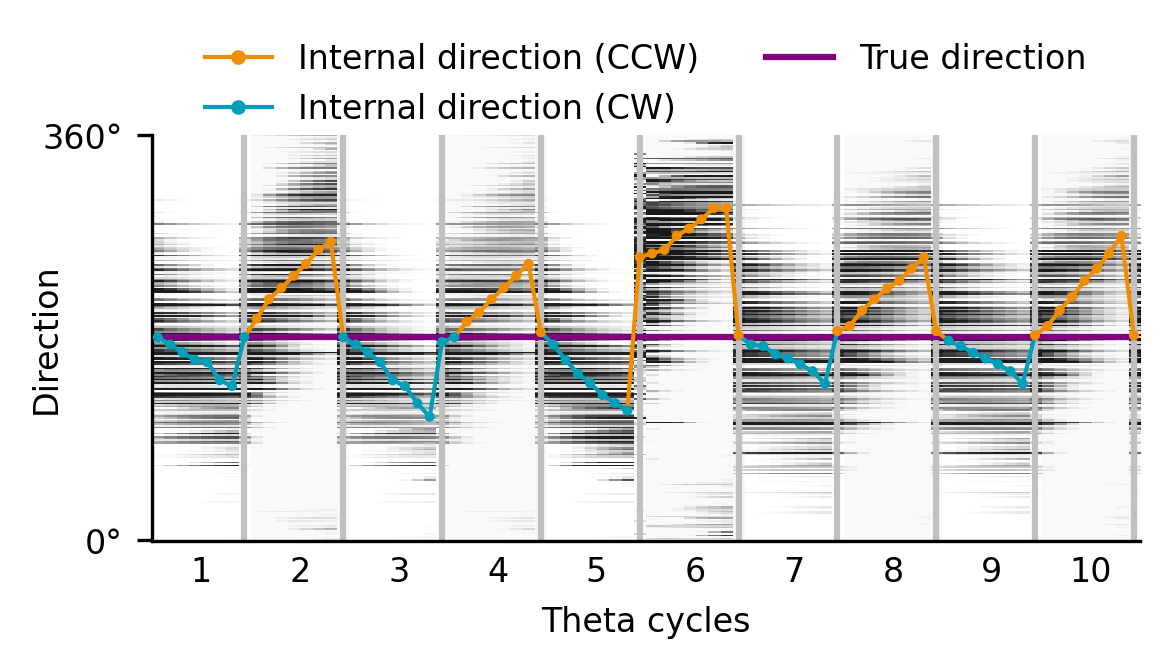

In [12]:
# Grid Cell Sweep - PV reset + model decoder
# 1) build session-averaged Conj and mEC hidden-state templates for each spatial bin from NORMAL dynamics
# 2) use those templates to RESET manipulated Conj and mEC hidden activity at reset steps
# 3) use MODEL mEC decoder for readout
# 4) keep Figure 1 = direction + heatmap, Figure 2 = XY trajectory
# 5) add NORMAL model rollout mEC trajectory to Figure 2
# 6) mark and label every reset point on manipulated decoded trajectory in Figure 2


import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from matplotlib.gridspec import GridSpec
from trajectory_generator_seed import TrajectoryGenerator
from matplotlib.collections import LineCollection

#Random Seeds
#seed_traj = 331
seed_traj=331
seed_shutdown = 626
seed_torch = 7

reset_point='last'
# --------------------------------------------------
# settings
# --------------------------------------------------
options.sequence_length = 80
options.batch_size = 20

block_len = 8
shutdown_frac = 0.2
dt = 0.02

# boxcar smoothing window for heatmap columns
smooth_win = 0   # odd integer, e.g. 3 / 5 / 7

rng = np.random.default_rng(seed_shutdown)
torch.manual_seed(seed_torch)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed_torch)


options.use_place_cells = True
options.use_direction_cells = True


# --------------------------------------------------
# LMN groups from existing ratemaps
# --------------------------------------------------
pref_bin = np.argmax(activations_lmn, axis=1)

peak_ccw = np.max(activations_lmn_ccw, axis=1)
peak_cw  = np.max(activations_lmn_cw, axis=1)

eps = 1e-12
ratio = peak_ccw / (peak_cw + eps)

idx_gt1 = np.where(ratio > 1)[0]   # CCW/CW > 1
idx_lt1 = np.where(ratio < 1)[0]   # CCW/CW < 1

idx_gt1 = idx_gt1[np.argsort(pref_bin[idx_gt1])]
idx_lt1 = idx_lt1[np.argsort(pref_bin[idx_lt1])]

print(f"n idx_gt1 = {len(idx_gt1)}")
print(f"n idx_lt1 = {len(idx_lt1)}")


# --------------------------------------------------
# get same trajectory
# --------------------------------------------------
trajectory_generator_joint = TrajectoryGenerator(
    options,
    place_cells=place_cells,
    direction_cells=direction_cells,
    seed=seed_traj
)

batch = trajectory_generator_joint.get_test_batch_straight()
ang_v, init_dir_actv, dc_outputs, mdir, s, init_actp, place_outputs, pos = unpack_batch(batch)

if s is None or init_actp is None or pos is None:
    raise ValueError(
        "Joint batch still not available. Make sure place_cells and direction_cells both exist."
    )

if isinstance(mdir, torch.Tensor):
    mdir_np = mdir.detach().cpu().numpy()
else:
    mdir_np = np.asarray(mdir)

if mdir_np.ndim == 3:
    mdir_np = mdir_np[..., 0]

if isinstance(pos, torch.Tensor):
    pos_np = pos.detach().cpu().numpy()
else:
    pos_np = np.asarray(pos)

angle_range = getattr(direction_cells, "angle_range", 2 * np.pi)


# --------------------------------------------------
# build reset tables from NORMAL dynamics
# --------------------------------------------------
pas_state_table, pas_state_count = build_empirical_pas_state_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    direction_cells=direction_cells,
    n_batches=50,
)

conj_template_table = build_empirical_conj_template_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    x_bins=25,
    y_bins=25,
    n_batches=80,
)

mec_template_table = build_empirical_mec_template_table(
    model=model,
    trajectory_generator=trajectory_generator_joint,
    x_bins=25,
    y_bins=25,
    n_batches=80,
)


# --------------------------------------------------
# run joint rollout with PV-template mEC reset
# --------------------------------------------------
with torch.no_grad():
    (
        lmn_block, pas_block, adap_block, conj_block, mec_block,
        shut_mask_record, source_blocks, shut_cells_per_block, reset_record
    ) = run_lmn_pas_conj_mec_with_blockwise_shutdown_and_joint_reset(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv),
        dc_outputs=dc_outputs,
        mdir=mdir,
        pos=pos,
        pas_state_table=pas_state_table,
        conj_template_table=conj_template_table,
        mec_template_table=mec_template_table,
        idx_gt1=idx_gt1,
        idx_lt1=idx_lt1,
        block_len=block_len,
        shutdown_frac=shutdown_frac,
        rng=rng,
        reset_point=reset_point
    )

    pas_preds_block = model.PaSDecoder(pas_block)
    mec_preds_block = model.mECDecoder(mec_block)

# PaS decoding
pred_pas_block = direction_cells.get_nearest_cell_dir(pas_preds_block).detach().cpu().numpy()
if pred_pas_block.ndim == 3 and pred_pas_block.shape[-1] == 1:
    pred_pas_block = pred_pas_block[..., 0]

# MEC readout now uses MODEL decoder
pred_pos_block = place_cells.get_nearest_cell_pos(mec_preds_block).detach().cpu().numpy()


# --------------------------------------------------
# normal rollout for comparison in figure 2
# --------------------------------------------------
with torch.no_grad():
    (
        lmn_normal, pas_normal, adap_normal, conj_normal, mec_normal
    ) = run_normal_lmn_pas_conj_mec_rollout(
        model=model,
        inputs=(s, init_actp, ang_v, init_dir_actv)
    )

    mec_preds_normal = model.mECDecoder(mec_normal)

pred_pos_normal = place_cells.get_nearest_cell_pos(mec_preds_normal).detach().cpu().numpy()


# --------------------------------------------------
# plotting data
# --------------------------------------------------
true_plot = wrap_to_pi(mdir_np)
pred_pas_plot = wrap_to_pi(pred_pas_block)

t = np.arange(mdir_np.shape[0])

center_shift = true_plot[:, [0]]
true_centered = wrap_to_pi(true_plot - center_shift)
pred_pas_centered = wrap_to_pi(pred_pas_plot - center_shift)

true_line = break_at_wrap(true_centered[:, 0])
pred_pas_line = break_at_wrap(pred_pas_centered[:, 0])


# --------------------------------------------------
# PaS heatmap
# --------------------------------------------------
pas_np = pas_block.detach().cpu().numpy()

pref_idx_pas = np.argmax(activations_pas, axis=1)
n_angle_bins = activations_pas.shape[1]

order_pas = np.argsort(pref_idx_pas)
pref_sorted = pref_idx_pas[order_pas]

pas_heat = pas_np[:, 0, order_pas].T

true_ang_0 = np.mod(mdir_np[:, 0], 2 * np.pi)
true_bin = np.floor(true_ang_0 / (2 * np.pi) * n_angle_bins).astype(int)
true_bin = np.clip(true_bin, 0, n_angle_bins - 1)

n_cells = pas_heat.shape[0]
center_row = n_cells // 2

pas_heat_centered = np.empty_like(pas_heat)
for tt in range(pas_heat.shape[1]):
    diffs = np.abs(pref_sorted - true_bin[tt])
    diffs = np.minimum(diffs, n_angle_bins - diffs)
    target_row = np.argmin(diffs)
    shift = center_row - target_row
    pas_heat_centered[:, tt] = np.roll(pas_heat[:, tt], shift)

pas_heat = pas_heat_centered

if smooth_win > 1:
    pas_heat = smooth_columns_boxcar(pas_heat, win=smooth_win)

n_rows_pas = pas_heat.shape[0]
center_row_pas = n_rows_pas // 2

pred_rel = wrap_to_pi(pred_pas_plot[:, 0] - true_plot[:, 0])
pred_row = center_row_pas + pred_rel / (2 * np.pi) * n_rows_pas
true_row = np.full_like(pred_row, center_row_pas, dtype=float)

true_row_line = break_rows_at_jump(true_row, n_rows=n_rows_pas)
pred_row_line = break_rows_at_jump(pred_row, n_rows=n_rows_pas)


# --------------------------------------------------
# true / decoded XY trajectory for batch 0
# rotate so true trajectory is horizontal
# --------------------------------------------------
true_xy = pos_np[:, 0, :]
pred_xy = pred_pos_block[:, 0, :]
pred_xy_normal = pred_pos_normal[:, 0, :]

true_xy_rot, pred_xy_rot, rot_theta = rotate_xy_to_horizontal(true_xy, pred_xy)

# rotate normal decoded trajectory using SAME transform
origin = true_xy[0].copy()
pred_xy_normal_centered = pred_xy_normal - origin
c = np.cos(-rot_theta)
s = np.sin(-rot_theta)
R = np.array([[c, -s],
              [s,  c]])
pred_xy_normal_rot = pred_xy_normal_centered @ R.T

reset_steps = np.where(reset_record)[0]
reset_xy_rot = pred_xy_rot[reset_steps]


# --------------------------------------------------
# Figure 1: first two panels together
# --------------------------------------------------
fig1, axes1 = plt.subplots(figsize=(4, 2.5), dpi=300)

for start in range(0, len(t), block_len):
    end = min(start + block_len, len(t))
    block_idx = start // block_len
    shade_color = 'white' if block_idx % 2 == 0 else 'lightgrey'
    axes1.axvspan(start - 0.5, end - 0.5, alpha=0.12, color=shade_color, lw=0)

for rs in reset_steps:
    axes1.axvline(rs, color='silver', linestyle='-', linewidth=1.5, alpha=1)

# 2) PaS heatmap + overlay
vmin_pas = np.percentile(pas_heat, 2)
vmax_pas = np.percentile(pas_heat, 95)

im1 = axes1.imshow(
    pas_heat,
    aspect='auto',
    origin='lower',
    interpolation='nearest',
    extent=[-0.5, len(t) - 0.5, -0.5, pas_heat.shape[0] - 0.5],
    vmin=vmin_pas,
    vmax=vmax_pas,
    cmap='Greys'
)



# Internal direction: color by whether it is above or below true direction
valid = np.isfinite(pred_row_line) & np.isfinite(true_row_line)

points = np.array([t, pred_row_line]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

seg_valid = valid[:-1] & valid[1:]
seg_mid = 0.5 * (pred_row_line[:-1] + pred_row_line[1:])
true_mid = 0.5 * (true_row_line[:-1] + true_row_line[1:])

seg_colors = np.where(
    seg_mid >= true_mid,
    '#F18D00',   # above true direction
    '#009FB9',   # below true direction
)

lc_pred = LineCollection(
    segments[seg_valid],
    colors=seg_colors[seg_valid],
    linewidths=1,
    zorder=6,
)
axes1.add_collection(lc_pred)

# markers, colored pointwise by position relative to true direction
point_colors = np.where(
    pred_row_line >= true_row_line,
    '#F18D00',
    '#009FB9',
)

axes1.scatter(
    t[valid],
    pred_row_line[valid],
    c=point_colors[valid],
    s=2,
    zorder=7,
)

axes1.plot([], [], color='#F18D00', linewidth=1, marker='o', markersize=2.5, label='Internal direction (CCW)')
axes1.plot([], [], color='#009FB9', linewidth=1, marker='o', markersize=2.5, label='Internal direction (CW)')

axes1.plot(
    t, true_row_line,
    color='purple',
    linewidth=1.5,
    label='True direction',
    zorder=5
)


axes1.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.3),
    ncol=2,
    facecolor='white',
    frameon=False,
    fontsize=8,
)


axes1.set_ylabel('Direction', fontsize=8, labelpad=-5)
axes1.set_yticks([0, n_rows_pas - 1])
axes1.set_yticklabels(['0°', '360°'])
# x-axis as theta cycles
cycle_starts = np.arange(0, len(t), block_len)
cycle_centers = cycle_starts + (block_len - 1) / 2
cycle_labels = np.arange(1, len(cycle_starts) + 1)

axes1.set_xticks(cycle_centers)
axes1.set_xticklabels(cycle_labels)
axes1.set_xlabel('Theta cycles', fontsize=8)

axes1.tick_params(axis='x', which='major', labelsize=8, length=0)
axes1.tick_params(axis='y', which='major', labelsize=8)

#ticksize as 8


sns.despine()
fig1.tight_layout()

#plt.savefig('./docs/directional_sweeps.pdf', format="pdf", dpi=300, bbox_inches="tight")

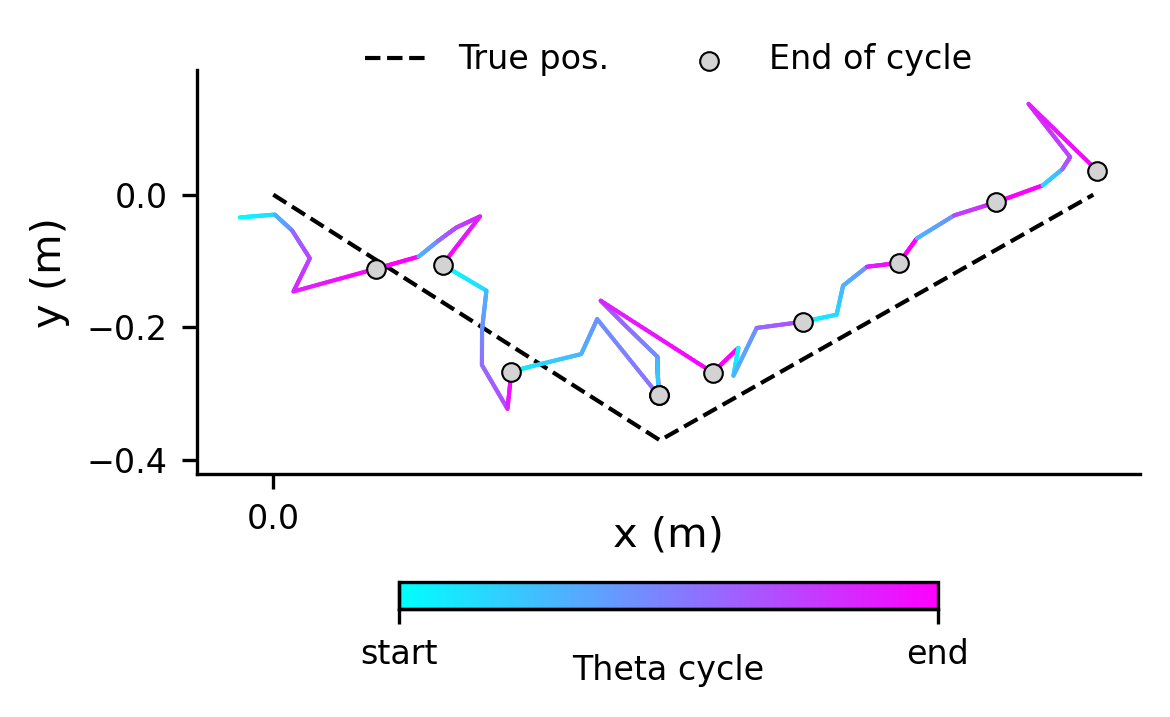

In [13]:


# --------------------------------------------------
# Figure 2: XY trajectory separate, with normal rollout
# --------------------------------------------------
fig2, axes2 = plt.subplots(figsize=(4, 2.5), dpi=300)

axes2.plot(
    true_xy_rot[:, 0], true_xy_rot[:, 1],
    color='black',
    linewidth=1,
    linestyle='--',
    label='True pos.',
    zorder=2
)

lc = build_colored_line_by_block(
    axes2,
    pred_xy_rot,
    block_len=block_len,
    cmap='cool',
    lw=1,
    alpha=1.0,
    zorder=3,
    sub_per_step=30
)


axes2.scatter(
    reset_xy_rot[:, 0],
    reset_xy_rot[:, 1],
    s=20,
    facecolors='lightgray',
    edgecolors='black',
    linewidths=0.5,
    zorder=6,
    label='End of cycle'
)

# for k, rs in enumerate(reset_steps):
#     axes2.annotate(
#         f"{rs}",
#         (reset_xy_rot[k, 0], reset_xy_rot[k, 1]),
#         textcoords="offset points",
#         xytext=(4, 4),
#         fontsize=8,
#         color='red',
#         zorder=7
#     )

axes2.set_xlabel('x (m)', labelpad=-5)
axes2.set_ylabel('y (m)')
#axes2.set_title('Rotated XY trajectory: true vs manipulated decoded vs normal decoded')
axes2.set_aspect('auto', adjustable='box')
axes2.legend(
    loc='upper center',
    bbox_to_anchor=(0.5, 1.1),
    borderaxespad=0.,
    fontsize=8,
    ncol=2,
    frameon=False,
)

#xticks as 0, 1.5
axes2.set_xticks([0, 1.5])

all_xy = np.vstack([true_xy_rot, pred_xy_rot, pred_xy_normal_rot])
xmin, ymin = np.min(all_xy, axis=0)
xmax, ymax = np.max(all_xy, axis=0)
xpad = 0.05 * max(xmax - xmin, 1e-6)
ypad = 0.10 * max(ymax - ymin, 1e-6)
axes2.set_xlim(xmin - xpad, xmax + xpad)
axes2.set_ylim(ymin - ypad, ymax + ypad)
#tick size as 8
axes2.tick_params(axis='both', which='major', labelsize=8)


cbar2 = fig2.colorbar(
    lc,
    ax=axes2,
    orientation='horizontal',
    location='bottom',
    fraction=0.05,
    pad=0.20,
)
cbar2.set_ticks([0.0, 1.0])
cbar2.set_ticklabels(['start', 'end'], fontsize=8)
cbar2.set_label('Theta cycle', fontsize=8, labelpad=-4)


sns.despine()

plt.tight_layout()


#plt.savefig('./docs/positional_sweeps.pdf', format="pdf", dpi=300, bbox_inches="tight")


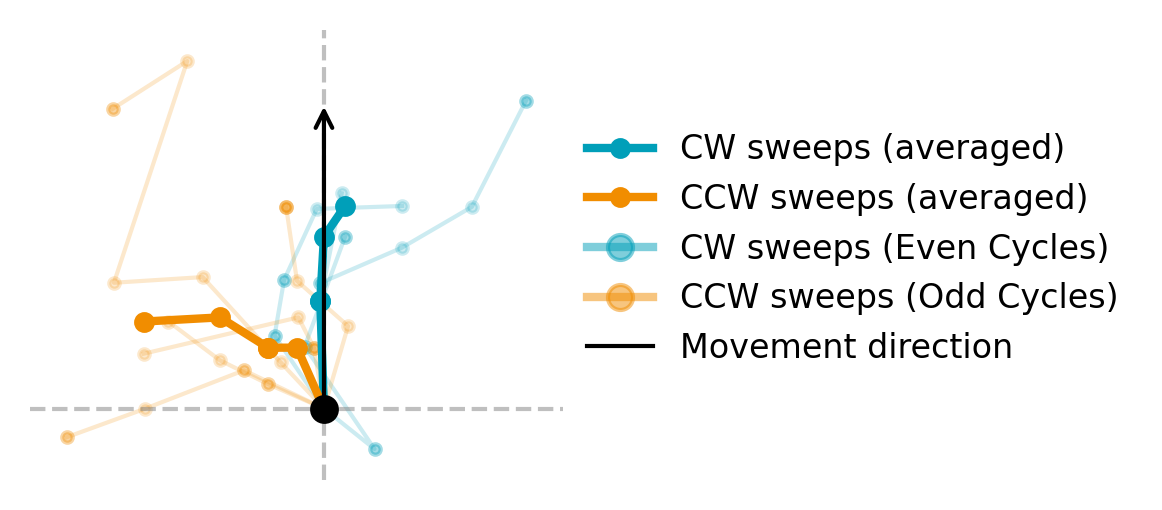

In [16]:


# --------------------------------------------------
# Figure 3: block-aligned trajectories
# - use points 0..block_len-1 in each block
# - exclude reset point
# - point 0 -> (0,0)
# - rotate by true direction at point 0 so it is vertical
# - show even/odd block medians
# --------------------------------------------------
# --------------------------------------------------
# Figure 3: overlapped version of 3a and 3b
# - all aligned blocks + pointwise medians on the same axis
# - 3a made more transparent
# --------------------------------------------------
aligned_blocks, block_ids, block_parity = build_aligned_block_trajectories(
    pred_xy=pred_xy,
    true_dir=mdir_np[:, 0],
    block_len=block_len
)

even_mask = (block_parity == 0)
odd_mask = (block_parity == 1)

aligned_even = aligned_blocks[even_mask]
aligned_odd = aligned_blocks[odd_mask]

median_even = pointwise_median_traj(aligned_even)
median_odd = pointwise_median_traj(aligned_odd)

fig3, ax3 = plt.subplots(1, 1, figsize=(4, 1.8), dpi=300)

# --------------------------------------------------
# first: plot all aligned blocks (old 3a), but more transparent
# --------------------------------------------------
for i, b in enumerate(block_ids):
    traj = aligned_blocks[i]
    color = '#009FB9' if (b % 2 == 0) else '#F18D00'

    ax3.plot(
        traj[:, 0], traj[:, 1],
        '-o',
        color=color,
        alpha=0.2,          # more transparent than before
        linewidth=1,
        markersize=2.5,
        zorder=1
    )

# --------------------------------------------------
# then: overlay medians (old 3b)
# --------------------------------------------------
if median_even is not None:
    ax3.plot(
        median_even[:, 0], median_even[:, 1],
        '-o',
        color='#009FB9',
        linewidth=2,
        markersize=4,
        label='CW sweeps (averaged)',
        zorder=4
    )


if median_odd is not None:
    ax3.plot(
        median_odd[:, 0], median_odd[:, 1],
        '-o',
        color='#F18D00',
        linewidth=2,
        markersize=4,
        label='CCW sweeps (averaged)',
        zorder=4
    )
    

# --------------------------------------------------
# origin and vertical reference
# --------------------------------------------------
ax3.scatter(0, 0, color='black', s=35, zorder=6)
ax3.axvline(0, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax3.axhline(0, color='gray', linestyle='--', linewidth=1, alpha=0.5)

arrow_len = 0.8 * max(
    1e-6,
    np.ptp(aligned_blocks[..., 1]) if aligned_blocks.size > 0 else 1.0
)
ax3.annotate(
    '',
    xy=(0, arrow_len),
    xytext=(0, 0),
    arrowprops=dict(arrowstyle='->', color='black', lw=1),
    zorder=7
)

# --------------------------------------------------
# legend
# --------------------------------------------------
ax3.plot([], [], '-o', color='#009FB9', alpha=0.5, lw=2, label='CW sweeps (Even Cycles)')
ax3.plot([], [], '-o', color='#F18D00', alpha=0.5, lw=2, label='CCW sweeps (Odd Cycles)')
ax3.plot([], [], color='black', linewidth=1, label='Movement direction')

ax3.legend(
    loc='upper left',
    bbox_to_anchor=(1.02, 0.8),
    borderaxespad=0,
    frameon=False, 
    fontsize=8
)

# --------------------------------------------------
# formatting
# --------------------------------------------------


ax3.set_xticks([])
ax3.set_yticks([])
ax3.set_aspect('auto', adjustable='box')

for spine in ax3.spines.values():
    spine.set_visible(False)

if aligned_blocks.size > 0:
    all_fig3_xy = aligned_blocks.reshape(-1, 2)
    xmin3, ymin3 = np.min(all_fig3_xy, axis=0)
    xmax3, ymax3 = np.max(all_fig3_xy, axis=0)
    xpad3 = 0.08 * max(xmax3 - xmin3, 1e-6)
    ypad3 = 0.08 * max(ymax3 - ymin3, 1e-6)

    ax3.set_xlim(xmin3 - xpad3, xmax3 + xpad3)
    ax3.set_ylim(ymin3 - ypad3, ymax3 + ypad3)

sns.despine(left=True, bottom=True)
plt.tight_layout()

#plt.savefig('./docs/aligned_sweeps.pdf', format="pdf", dpi=300, bbox_inches="tight")



